# Single-cell RNA-seq analysis with Seurat v5 in R
### Diabetic kidney disease (DKD) vs normal human kidney: GEO GSE209781

A complete, runnable walk-through of a single-cell RNA-seq analysis: from raw 10x count matrices to annotated cell types and a DKD-vs-normal differential expression test. Every step has a short explanation of **what** it does and **why**, and the saved outputs show what you should expect to see.

**Dataset.** GEO series [GSE209781](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE209781): human kidney samples in 10x Genomics format, 3 normal (NM01 to NM03) and 3 DKD (DKD01 to DKD03). After quality control the analysis keeps **2,850 cells** (1,325 normal, 1,525 DKD).

**Pipeline**

```text
raw 10x matrices -> Seurat objects -> QC filtering -> normalization -> variable genes
   -> integration (CCA anchors) -> scaling (+ cell-cycle check) -> PCA
   -> neighbours / clusters / UMAP -> marker genes
   -> annotation (SingleR | marker-based | reference mapping)
   -> final annotation review -> DKD vs Normal differential expression (limma)
```

**Contents**

0. Setup
1. Data import
2. Quality control
3. Normalization
4. Highly variable features
5. Integration
6. Scaling
7. Sample metadata
8. Cell-cycle check
9. PCA and choosing the number of dimensions
10. Clustering, t-SNE and UMAP
11. Marker genes
12. Cell-type annotation (three methods)
13. Final annotation review: choose which labels to keep
14. Differential expression: DKD vs Normal

**Before you start**

* Use an **R runtime** in Colab (Runtime -> Change runtime type -> R).
* Mount Google Drive (see section 0.1) so packages and checkpoints survive between sessions.
* The first run installs many packages and downloads about 1 GB of data, so it is slow; later sessions are much faster.
* Saved outputs were produced with R 4.6, Seurat 5.5.1 and Bioconductor 3.23.

## 0. Setup

### 0.1 Mount Google Drive and set up folders

Colab sessions are temporary: everything in `/content` disappears when the session ends. Google Drive gives us two persistent places:

* `R_lib`: a package library, so Seurat and the Bioconductor packages only have to be installed once.
* `proj_dir`: a project folder for checkpoints and result files.

> **Mounting Drive in an R runtime:** open the **Files** panel (folder icon in the left sidebar) and click **Mount Drive**. The Python snippet `drive.mount()` is for Python runtimes. If you skip this step the notebook falls back to temporary folders: everything still runs, but nothing is kept between sessions.

In [ ]:
# Is Google Drive mounted?
drive_ok <- dir.exists("/content/drive/MyDrive")

if (drive_ok) {
  proj_dir <- "/content/drive/MyDrive/scRNA/GSEKeramati"   # checkpoints and results
  R_lib    <- "/content/drive/MyDrive/R_lib/site-library"  # installed packages
} else {
  proj_dir <- "/content/scRNA_output"                      # lost when the session ends
  R_lib    <- "/content/R_lib"
  message("Google Drive is not mounted: packages and results will not persist between sessions.")
}
dir.create(proj_dir, recursive = TRUE, showWarnings = FALSE)
dir.create(R_lib,    recursive = TRUE, showWarnings = FALSE)

.libPaths(c(R_lib, .libPaths()))   # R looks in R_lib first
.libPaths()

### 0.2 Install packages (first run only)

Seurat has many dependencies, so installation can take 10+ minutes. The cell below installs only what is missing, into `R_lib`, and does nothing on later runs.

| Package | Used for |
| --- | --- |
| **Seurat** | the whole workflow: objects, QC, normalization, integration, clustering, markers, label transfer |
| ggplot2, patchwork | plotting and combining plots (`p1 + p2`) |
| dplyr | tidy summaries of marker tables |
| clustree | choosing a clustering resolution |
| future | parallel back-end used by Seurat |
| readxl | reading the CellMarker database (Excel) |
| **SingleR**, **celldex** | automatic annotation against reference datasets |
| SingleCellExperiment | object type that SingleR works on |
| **limma** | differential expression (DKD vs Normal) |

> If an install fails with a "non-zero exit status", an interrupted earlier install has usually left a stale lock folder (`00LOCK...`). The first line of the cell removes those.

In [ ]:
# Run once. Skips anything that is already installed in R_lib.
unlink(file.path(R_lib, "00LOCK*"), recursive = TRUE)   # clear stale locks from interrupted installs

is_installed <- function(pkg) requireNamespace(pkg, quietly = TRUE)

cran_pkgs <- c("Seurat", "ggplot2", "patchwork", "dplyr", "clustree",
               "future", "readxl", "BiocManager")
bioc_pkgs <- c("SingleR", "celldex", "SingleCellExperiment", "limma")

todo_cran <- cran_pkgs[!vapply(cran_pkgs, is_installed, logical(1))]
if (length(todo_cran) > 0) install.packages(todo_cran, lib = R_lib)

todo_bioc <- bioc_pkgs[!vapply(bioc_pkgs, is_installed, logical(1))]
if (length(todo_bioc) > 0) BiocManager::install(todo_bioc, lib = R_lib, ask = FALSE, update = FALSE)

### 0.3 Load the core libraries

Packages that are only needed later (dplyr, clustree, SingleR, limma, ...) are loaded in the section where they are first used, so you can see what each one is for.

In [ ]:
library(Seurat)
packageVersion("Seurat")   # 5.5.1 when this notebook was run
library(ggplot2)
library(patchwork)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.6.0 but the current version is
4.6.1; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed

‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t

[1] ‘5.5.1’

## 1. Data import

### 1.1 Download the raw data from GEO

`GSE209781_RAW.tar` (about 1 GB) holds one 10x matrix per sample. R's default download time-out is only 60 seconds, which cuts a download of this size short (error: *downloaded length != reported length*), so we raise it first.

In [ ]:
data_dir <- "/content/data"
dir.create(data_dir, showWarnings = FALSE)

options(timeout = 3600)   # default is 60 s, far too short for a 1 GB file
download.file(
  "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE209nnn/GSE209781/suppl/GSE209781_RAW.tar",
  destfile = file.path(data_dir, "GSE209781_RAW.tar"),
  mode = "wb"
)
untar(file.path(data_dir, "GSE209781_RAW.tar"), exdir = data_dir)
list.files(data_dir)

> **Expected folder layout.** `Read10X()` reads one **folder per sample** that contains the three standard files `barcodes.tsv.gz`, `features.tsv.gz` and `matrix.mtx.gz`. The rest of the notebook expects these folders:
>
> `/content/data/NM01`, `NM02`, `NM03` (normal) and `DKD01`, `DKD02`, `DKD03` (diabetic kidney disease).
>
> After extracting the tar file, move each sample's three files into its folder and rename them to the standard names. This step depends on the file names inside the archive, so adapt it to what `list.files()` shows.

### 1.2 Normal samples

`Read10X()` loads the sparse count matrix (genes x barcodes) and `CreateSeuratObject()` wraps it in a Seurat object.

The matrices from GEO are **raw, unfiltered**: they contain every possible barcode (about 6.8 million columns), almost all of them empty droplets. So `min.features` does double duty as a crude *cell-calling* filter: it keeps only barcodes with at least that many detected genes (4,000 for NM01, 2,500 for NM02, 3,500 for NM03, set per sample). `min.cells` drops genes seen in too few cells.

In [ ]:
NM1_data <- Read10X(file.path(data_dir, "NM01"))

In [ ]:
length(NM1_data@Dimnames[[1]]) # number of genes
length(NM1_data@Dimnames[[2]]) # number of barcodes (almost all are empty droplets)

[1] 36601

[1] 6794880

In [ ]:
NM1 <- CreateSeuratObject(NM1_data, project = "GSE209781", min.cells = 10, min.features = 4000)
head(NM1@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA
,<fct>,<dbl>,<int>
AAACGAACACACGGAA-1,GSE209781,17452,4232
AAAGAACCATGACGGA-1,GSE209781,23035,5018
AAAGGATGTCCCTGAG-1,GSE209781,77965,8956
AAAGGATTCGCCCAGA-1,GSE209781,20485,5114
AAAGGATTCGGTAACT-1,GSE209781,21860,5092
AAAGGGCAGCCAAGTG-1,GSE209781,26464,4757


**Sanity check: where do the metadata columns come from?** Pull the count matrix out of the object and compare. `nCount_RNA` is the column sum (total UMIs) and `nFeature_RNA` is the number of genes with a non-zero count.

In [ ]:
count_matrix_NM1 <- GetAssayData(NM1, assay = "RNA", layer = "counts")
count_matrix_NM1 <- as.data.frame(as.matrix(count_matrix_NM1))

dim(count_matrix_NM1)                        # genes x cells that passed the filters
head(count_matrix_NM1)
colSums(count_matrix_NM1[, 1:2])             # = nCount_RNA of the first two cells (17452, 23035)
length(which(count_matrix_NM1[, 1] != 0))    # = nFeature_RNA of the first cell (4232)

[1] 17632   917

,AAACGAACACACGGAA-1,AAAGAACCATGACGGA-1,AAAGGATGTCCCTGAG-1,AAAGGATTCGCCCAGA-1,AAAGGATTCGGTAACT-1,AAAGGGCAGCCAAGTG-1,AAAGGTAAGCCAAGCA-1,AAAGTCCCAATTCACG-1,AAAGTGAGTTCTTGTT-1,AACAAAGGTACAACGG-1,⋯,TTTCCTCTCGTGGGAA-1,TTTCGATAGCTGGCCT-1,TTTCGATCAATTGTGC-1,TTTCGATTCTTCTGGC-1,TTTGACTTCATGAGAA-1,TTTGATCCACAAGCCC-1,TTTGATCGTACTCGAT-1,TTTGGTTCAACGGCCT-1,TTTGTTGCAGGTTTAC-1,TTTGTTGTCATTGGTG-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AL627309.1,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
AL627309.5,1,1,0,1,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC01409,0,0,0,0,0,0,1,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC01128,0,0,1,0,1,0,0,0,0,0,⋯,0,0,0,0,1,0,0,3,0,0
LINC00115,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
FAM41C,0,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


AAACGAACACACGGAA-1 AAAGAACCATGACGGA-1 
             17452              23035

[1] 4232

Import the other two normal samples the same way, then **merge** the three into one object. `add.cell.ids` prefixes every cell name with its sample (`Normal-1_...`), which keeps barcodes unique and records the origin of each cell.

In [ ]:
NM2_data <- Read10X(file.path(data_dir, "NM02"))
NM2 <- CreateSeuratObject(NM2_data, project = "GSE209781", min.cells = 5, min.features = 2500)

NM3_data <- Read10X(file.path(data_dir, "NM03"))
NM3 <- CreateSeuratObject(NM3_data, project = "GSE209781", min.cells = 10, min.features = 3500)

normals <- merge(NM1, c(NM2, NM3), add.cell.ids = c("Normal-1", "Normal-2", "Normal-3"))
head(normals)

,orig.ident,nCount_RNA,nFeature_RNA
,<chr>,<dbl>,<int>
Normal-1_AAACGAACACACGGAA-1,GSE209781,17452,4232
Normal-1_AAAGAACCATGACGGA-1,GSE209781,23035,5018
Normal-1_AAAGGATGTCCCTGAG-1,GSE209781,77965,8956
Normal-1_AAAGGATTCGCCCAGA-1,GSE209781,20485,5114
Normal-1_AAAGGATTCGGTAACT-1,GSE209781,21860,5092
Normal-1_AAAGGGCAGCCAAGTG-1,GSE209781,26464,4757
Normal-1_AAAGGTAAGCCAAGCA-1,GSE209781,190408,10727
Normal-1_AAAGTCCCAATTCACG-1,GSE209781,23612,5038
Normal-1_AAAGTGAGTTCTTGTT-1,GSE209781,25720,4613


**Seurat v5 keeps each sample as a separate layer.** After merging, the RNA assay holds `counts.1`, `counts.2`, `counts.3` (one per sample) instead of a single `counts` matrix. Individual layers can be pulled out with `GetAssayData(..., layer = "counts.2")`.

In [ ]:
normals@assays

$RNA
Assay (v5) data with 20035 features for 2909 cells
First 10 features:
 AL627309.1, AL627309.5, LINC01409, LINC01128, LINC00115, FAM41C,
LINC02593, SAMD11, NOC2L, KLHL17 
Layers:
 counts.1, counts.2, counts.3 


In [ ]:
count_matrix_NM2 <- GetAssayData(normals, assay = "RNA", layer = "counts.2")
count_matrix_NM2 <- as.data.frame(as.matrix(count_matrix_NM2))
dim(count_matrix_NM2)
head(count_matrix_NM2)

[1] 18912   945

,Normal-2_AAACCCATCTAAGAAG-1,Normal-2_AAAGGATAGATTGTGA-1,Normal-2_AAAGGGCTCCTAGCCT-1,Normal-2_AAAGGTACAAAGCACG-1,Normal-2_AAAGTCCTCTGCACCT-1,Normal-2_AAAGTGAAGCTCGACC-1,Normal-2_AAAGTGAGTCGTGCCA-1,Normal-2_AACACACTCACGATCA-1,Normal-2_AACAGGGAGGGCAAGG-1,Normal-2_AACCCAATCAAGAAAC-1,⋯,Normal-2_TTTCCTCGTTTACACG-1,Normal-2_TTTCCTCTCAATGCAC-1,Normal-2_TTTGACTTCCGAGAAG-1,Normal-2_TTTGATCCACAACCGC-1,Normal-2_TTTGGAGAGGTTACCT-1,Normal-2_TTTGGAGCATCCTCAC-1,Normal-2_TTTGGAGGTCTGTTAG-1,Normal-2_TTTGGAGTCCTTTAGT-1,Normal-2_TTTGGTTAGGCTCCCA-1,Normal-2_TTTGGTTAGTTACTCG-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AL627309.1,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
AL627309.5,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC01409,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC01128,0,0,0,0,0,0,0,0,1,1,⋯,0,0,0,1,0,0,0,0,1,0
LINC00115,1,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
FAM41C,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


### 1.3 DKD samples

Same procedure for the three diabetic kidney disease samples.

In [ ]:
DKD1_data <- Read10X(file.path(data_dir, "DKD01"))
DKD1 <- CreateSeuratObject(DKD1_data, project = "GSE209781", min.cells = 10, min.features = 4500)

DKD2_data <- Read10X(file.path(data_dir, "DKD02"))
DKD2 <- CreateSeuratObject(DKD2_data, project = "GSE209781", min.cells = 10, min.features = 4500)

DKD3_data <- Read10X(file.path(data_dir, "DKD03"))
DKD3 <- CreateSeuratObject(DKD3_data, project = "GSE209781", min.cells = 10, min.features = 4000)

DKDs <- merge(DKD1, c(DKD2, DKD3), add.cell.ids = c("DKD-01", "DKD-02", "DKD-03"))
head(DKDs)

,orig.ident,nCount_RNA,nFeature_RNA
,<chr>,<dbl>,<int>
DKD-01_AAACCCACAGCTGTAT-1,GSE209781,23661,4626
DKD-01_AAACGAAGTTGACTGT-1,GSE209781,20346,5339
DKD-01_AAACGAATCACATTGG-1,GSE209781,28180,5639
DKD-01_AAACGCTAGGATATAC-1,GSE209781,52884,8238
DKD-01_AAAGAACCATAGTCAC-1,GSE209781,41564,6790
DKD-01_AAAGAACTCTACTATC-1,GSE209781,33109,5025
DKD-01_AAAGGATAGATGGTAT-1,GSE209781,35476,5193
DKD-01_AAAGGATCAGGTCTCG-1,GSE209781,65153,5837
DKD-01_AAAGGATGTAGTCACT-1,GSE209781,56078,5684


### 1.4 Checkpoint

Save the merged objects so you can resume later without re-reading the large raw matrices. `save.image()` stores the whole workspace on Drive; `load()` restores it. The `load()` line is commented out so that running the notebook top to bottom does not overwrite your current objects. Uncomment it when you start a new session and want to continue from here.

In [ ]:
SaveSeuratRds(normals, file = file.path(data_dir, "normals.Rds"))
SaveSeuratRds(DKDs,    file = file.path(data_dir, "DKDs.Rds"))

save.image(file.path(proj_dir, "scRNA_Keramati.RData"))     # whole workspace
# load(file.path(proj_dir, "scRNA_Keramati.RData"))         # <- uncomment to resume in a new session

## 2. Quality control

Low-quality barcodes distort every later step, so we remove them. Three standard metrics per cell:

| Metric | Meaning | Problem when |
| --- | --- | --- |
| `nFeature_RNA` | number of genes detected | **too low**: empty droplet or dying cell; **too high**: possible doublet |
| `nCount_RNA` | total UMIs | **too high**: possible doublet |
| `percent.mt` | % of UMIs from mitochondrial genes (`MT-` prefix in human) | **high**: stressed or broken cell (cytoplasmic RNA leaked out) |

Look at the distributions first, then choose cut-offs. Kidney tissue contains many mitochondria-rich tubular cells, so `percent.mt` is naturally wide here (see the violin plot) and the cut-off is a trade-off between removing damaged cells and keeping genuine tubular cells. We keep cells with

> 200 < `nFeature_RNA` < 15,000, `nCount_RNA` < 50,000, `percent.mt` < 20

### 2.1 Normal samples

In [ ]:
normals[["percent.mt"]] <- PercentageFeatureSet(normals, pattern = "^MT-")
head(normals@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt
,<chr>,<dbl>,<int>,<dbl>
Normal-1_AAACGAACACACGGAA-1,GSE209781,17452,4232,21.45313
Normal-1_AAAGAACCATGACGGA-1,GSE209781,23035,5018,22.85218
Normal-1_AAAGGATGTCCCTGAG-1,GSE209781,77965,8956,15.57237
Normal-1_AAAGGATTCGCCCAGA-1,GSE209781,20485,5114,26.39980
Normal-1_AAAGGATTCGGTAACT-1,GSE209781,21860,5092,18.55901
Normal-1_AAAGGGCAGCCAAGTG-1,GSE209781,26464,4757,47.74033


Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”

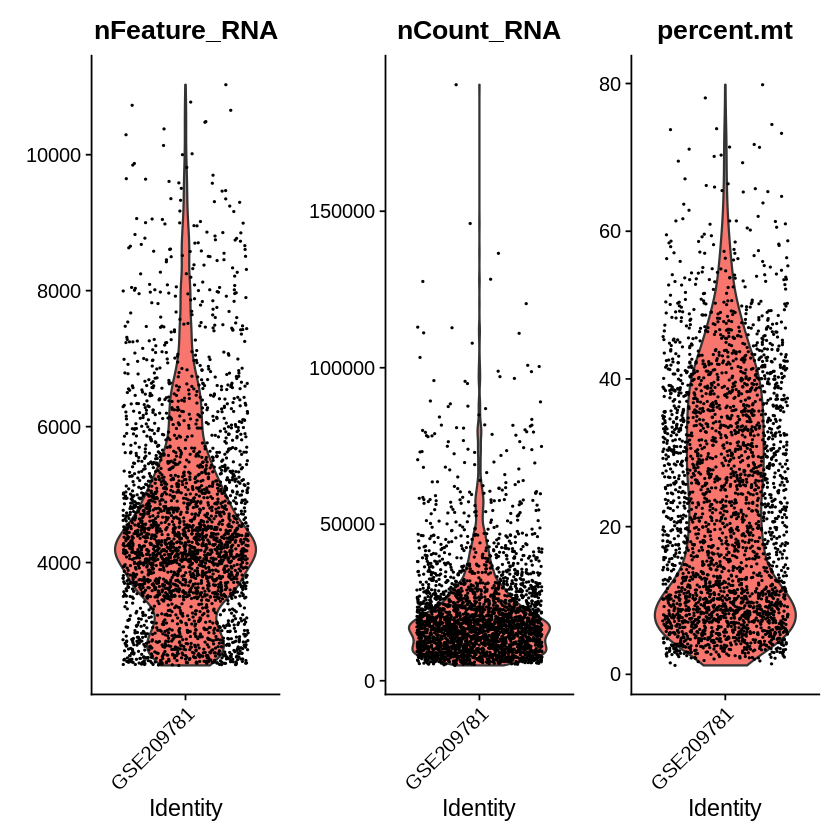

In [ ]:
VlnPlot(normals, features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), ncol = 3)

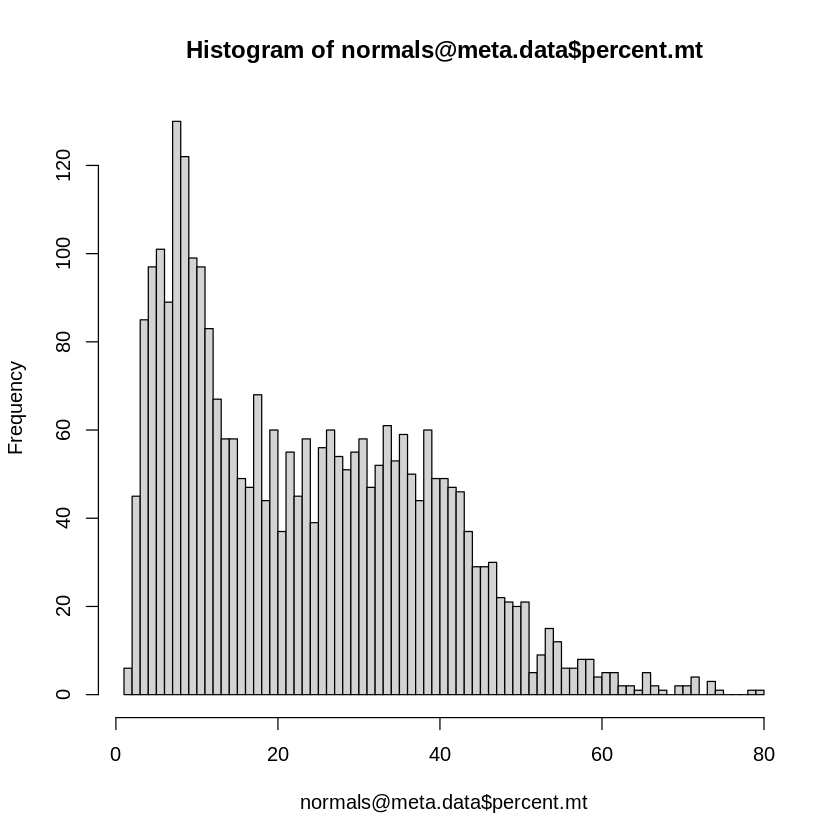

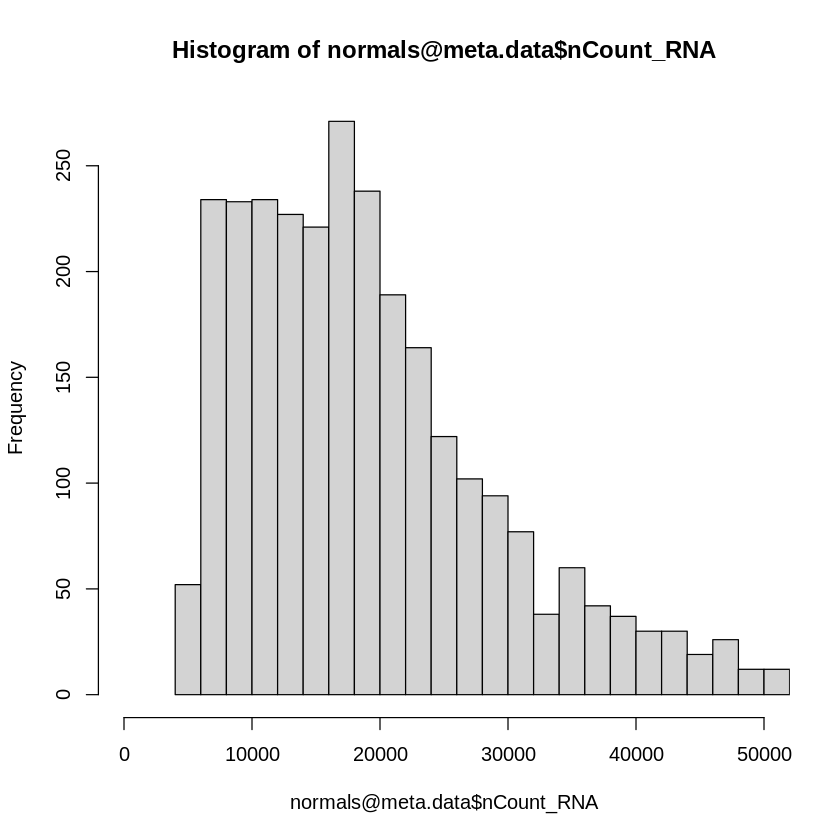

In [ ]:
hist(normals@meta.data$percent.mt, breaks = 100)
hist(normals@meta.data$nCount_RNA, breaks = 100, xlim = c(0, 50000))

In [ ]:
normals <- subset(normals, nFeature_RNA > 200 & nFeature_RNA < 15000 & percent.mt < 20 & nCount_RNA < 50000)
head(normals)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt
,<chr>,<dbl>,<int>,<dbl>
Normal-1_AAAGGATTCGGTAACT-1,GSE209781,21860,5092,18.559012
Normal-1_AAAGTCCCAATTCACG-1,GSE209781,23612,5038,19.981365
Normal-1_AACAAAGGTACAACGG-1,GSE209781,21160,4523,8.279773
Normal-1_AACAACCTCATTCCTA-1,GSE209781,19835,5285,15.875977
Normal-1_AACCAACAGTGATAAC-1,GSE209781,16605,4081,16.121650
Normal-1_AACCAACCATAGAGGC-1,GSE209781,23874,4416,1.415766
Normal-1_AACCACAAGGGATGTC-1,GSE209781,14565,4120,18.812221
Normal-1_AACGTCACAAACTAGA-1,GSE209781,20420,4175,19.853085
Normal-1_AAGACTCCACGCGCTA-1,GSE209781,10556,4044,4.727169


After filtering, `nCount_RNA` and `nFeature_RNA` should rise together (more UMIs, more genes detected). The scatter plot with a linear fit is a quick check that no obvious outlier population remains.

`geom_smooth()` using formula = 'y ~ x'

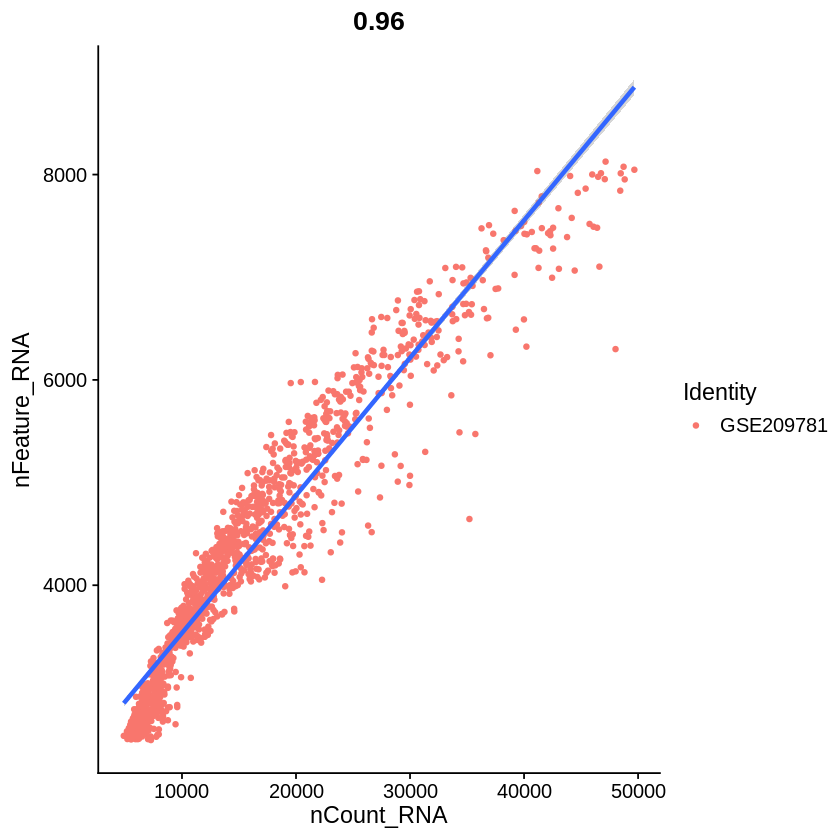

In [ ]:
FeatureScatter(normals, feature1 = "nCount_RNA", feature2 = "nFeature_RNA") + geom_smooth(method = "lm")

### 2.2 DKD samples

In [ ]:
DKDs[["percent.mt"]] <- PercentageFeatureSet(DKDs, pattern = "^MT-")
head(DKDs@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt
,<chr>,<dbl>,<int>,<dbl>
DKD-01_AAACCCACAGCTGTAT-1,GSE209781,23661,4626,33.925024
DKD-01_AAACGAAGTTGACTGT-1,GSE209781,20346,5339,12.788755
DKD-01_AAACGAATCACATTGG-1,GSE209781,28180,5639,28.534422
DKD-01_AAACGCTAGGATATAC-1,GSE209781,52884,8238,20.707586
DKD-01_AAAGAACCATAGTCAC-1,GSE209781,41564,6790,7.484843
DKD-01_AAAGAACTCTACTATC-1,GSE209781,33109,5025,46.331813


Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”

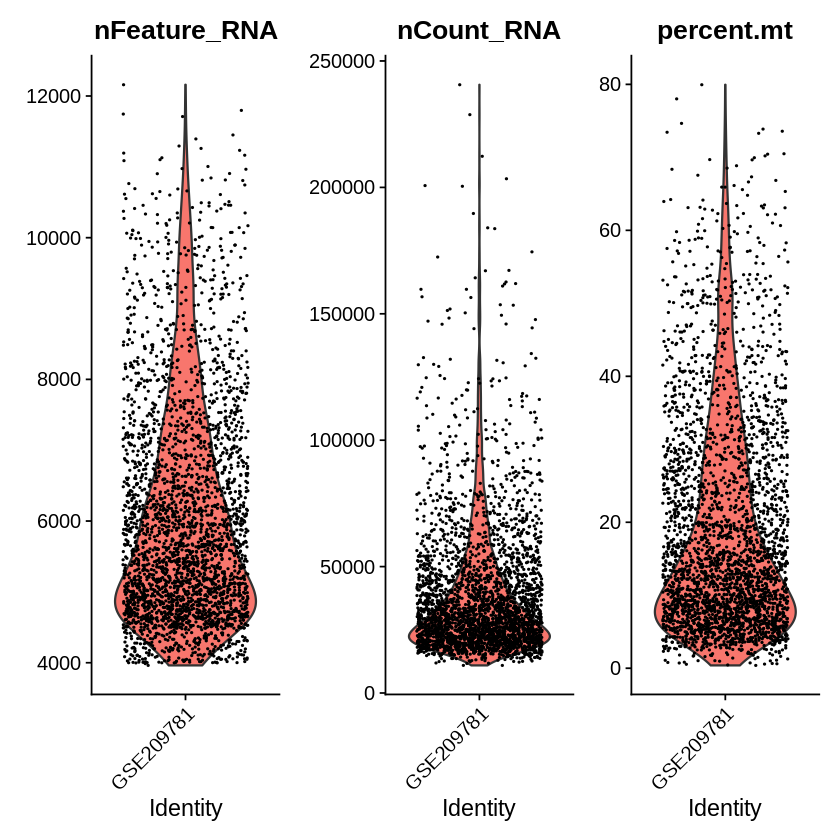

In [ ]:
VlnPlot(DKDs, features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), ncol = 3)

`geom_smooth()` using formula = 'y ~ x'

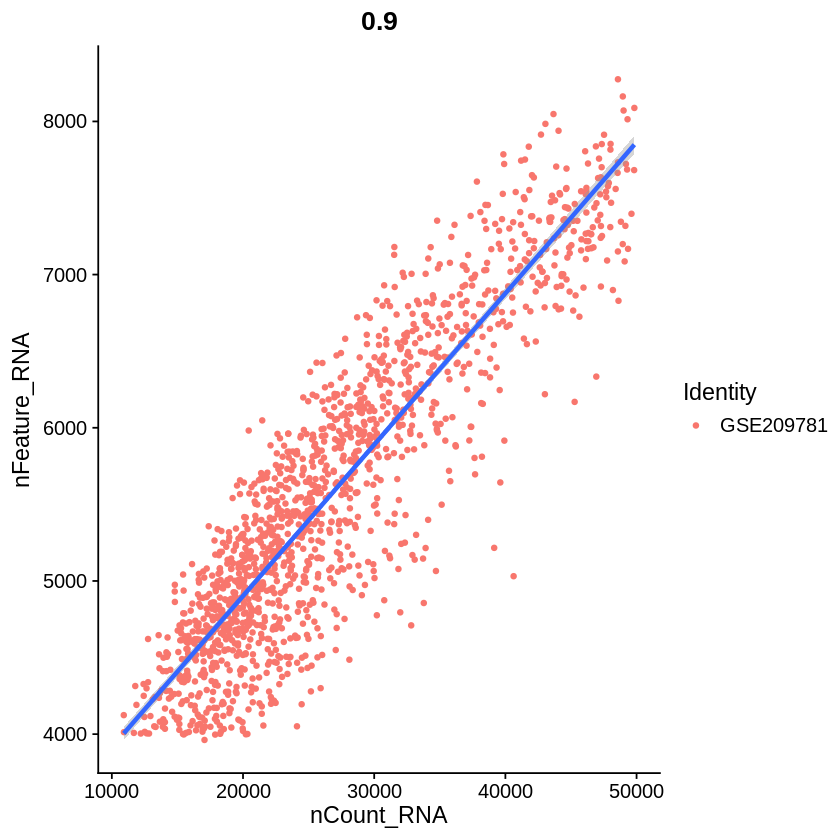

In [ ]:
DKDs <- subset(DKDs, nFeature_RNA > 200 & nFeature_RNA < 15000 & percent.mt < 20 & nCount_RNA < 50000)
FeatureScatter(DKDs, feature1 = "nCount_RNA", feature2 = "nFeature_RNA") + geom_smooth(method = "lm")

## 3. Normalization

Cells differ in how much RNA was captured and sequenced, so raw counts are not comparable between cells. `NormalizeData()` fixes this with **log-normalization**: divide each gene's count by the cell's total counts, multiply by 10,000, then take `log1p`. The result is stored in the `data` layer (raw counts stay in `counts`).

In [ ]:
# default: normalization.method = "LogNormalize", scale.factor = 10000
normals <- NormalizeData(normals)
DKDs    <- NormalizeData(DKDs)

Normalizing layer: counts.1

Normalizing layer: counts.2

Normalizing layer: counts.3

Normalizing layer: counts.1

Normalizing layer: counts.2

Normalizing layer: counts.3

**Before vs after** (first 50 cells of normal sample 2). Raw counts differ greatly between cells; after normalization the per-cell distributions are comparable.

In [ ]:
count_matrix_raw_2 <- GetAssayData(normals, assay = "RNA", layer = "counts.2")
count_matrix_raw_2 <- as.data.frame(as.matrix(count_matrix_raw_2))
head(count_matrix_raw_2)

,Normal-2_AAACCCATCTAAGAAG-1,Normal-2_AAAGGATAGATTGTGA-1,Normal-2_AAAGGTACAAAGCACG-1,Normal-2_AAAGTGAAGCTCGACC-1,Normal-2_AACACACTCACGATCA-1,Normal-2_AACAGGGAGGGCAAGG-1,Normal-2_AACCCAATCAAGAAAC-1,Normal-2_AACGAAACATCCCACT-1,Normal-2_AACTTCTCATGACTAC-1,Normal-2_AACTTCTGTCGAATTC-1,⋯,Normal-2_TTTCAGTTCAACTTTC-1,Normal-2_TTTCAGTTCGCGTAGC-1,Normal-2_TTTCCTCGTTTACACG-1,Normal-2_TTTCCTCTCAATGCAC-1,Normal-2_TTTGACTTCCGAGAAG-1,Normal-2_TTTGATCCACAACCGC-1,Normal-2_TTTGGAGGTCTGTTAG-1,Normal-2_TTTGGAGTCCTTTAGT-1,Normal-2_TTTGGTTAGGCTCCCA-1,Normal-2_TTTGGTTAGTTACTCG-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AL627309.1,0,0,0,0,0,0,0,0,0,1,⋯,0,0,0,0,0,0,0,0,0,0
AL627309.5,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC01409,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC01128,0,0,0,0,0,1,1,0,0,0,⋯,1,0,0,0,0,1,0,0,1,0
LINC00115,1,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
FAM41C,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


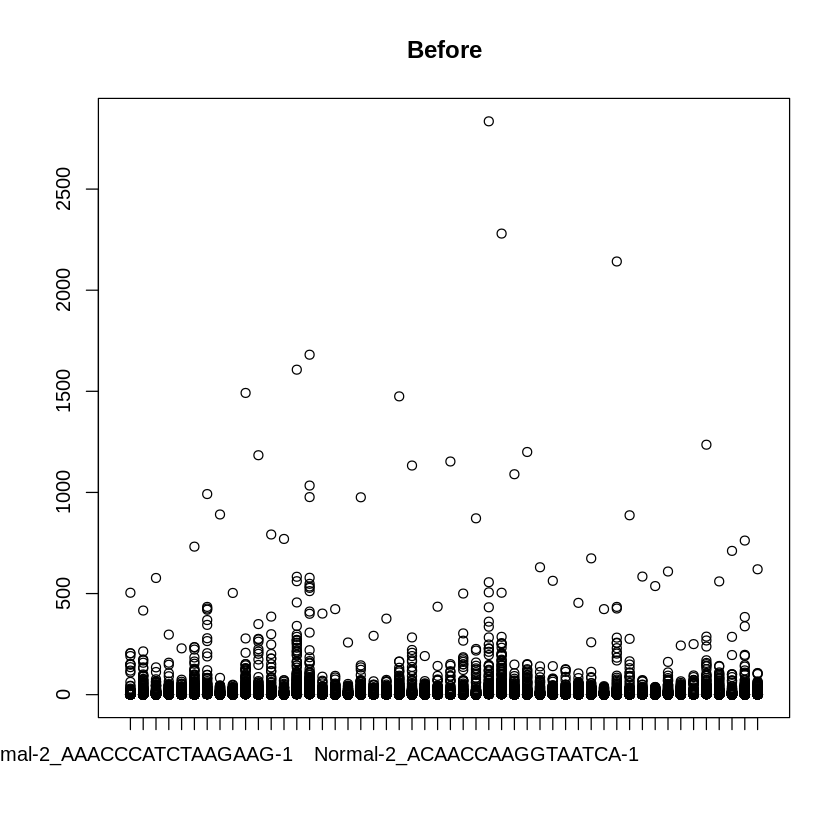

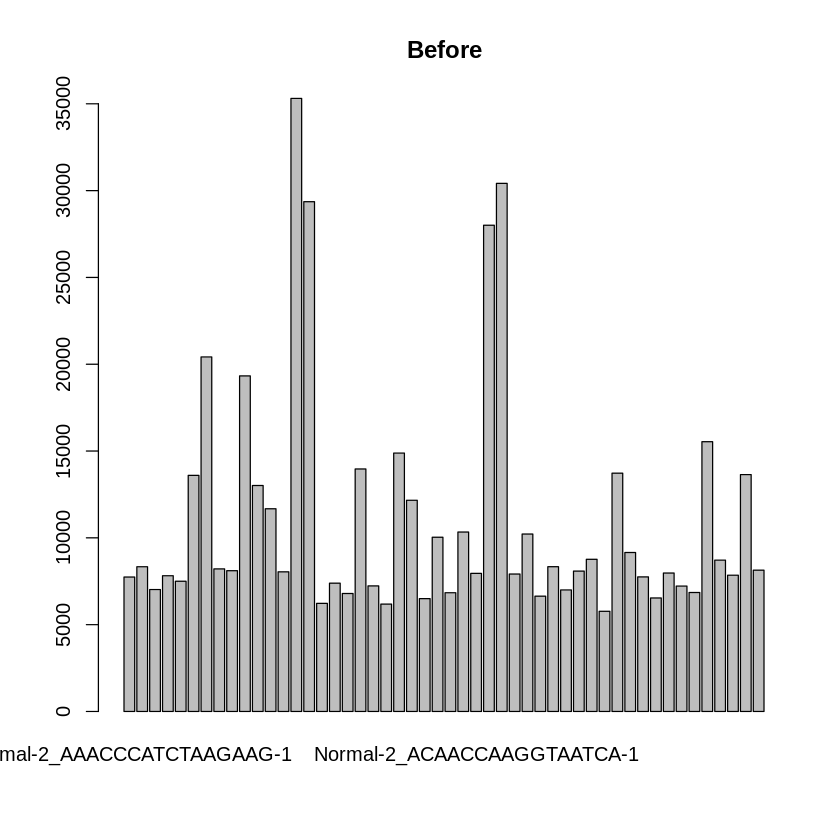

In [ ]:
boxplot((count_matrix_raw_2)[, 1:50], main = "Before")
barplot(colSums(count_matrix_raw_2)[1:50], main = "Before")

* **After normalization**

In [ ]:
count_matrix_norm_2 <- GetAssayData(normals, assay = "RNA", layer = "data.2")
count_matrix_norm_2 <- as.data.frame(as.matrix(count_matrix_norm_2))
head(count_matrix_norm_2)

,Normal-2_AAACCCATCTAAGAAG-1,Normal-2_AAAGGATAGATTGTGA-1,Normal-2_AAAGGTACAAAGCACG-1,Normal-2_AAAGTGAAGCTCGACC-1,Normal-2_AACACACTCACGATCA-1,Normal-2_AACAGGGAGGGCAAGG-1,Normal-2_AACCCAATCAAGAAAC-1,Normal-2_AACGAAACATCCCACT-1,Normal-2_AACTTCTCATGACTAC-1,Normal-2_AACTTCTGTCGAATTC-1,⋯,Normal-2_TTTCAGTTCAACTTTC-1,Normal-2_TTTCAGTTCGCGTAGC-1,Normal-2_TTTCCTCGTTTACACG-1,Normal-2_TTTCCTCTCAATGCAC-1,Normal-2_TTTGACTTCCGAGAAG-1,Normal-2_TTTGATCCACAACCGC-1,Normal-2_TTTGGAGGTCTGTTAG-1,Normal-2_TTTGGAGTCCTTTAGT-1,Normal-2_TTTGGTTAGGCTCCCA-1,Normal-2_TTTGGTTAGTTACTCG-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AL627309.1,0.0000000,0,0,0,0,0.0000000,0.0000000,0,0,0.4169879,⋯,0.0000000,0,0,0,0,0.0000000,0,0,0.0000000,0
AL627309.5,0.0000000,0,0,0,0,0.0000000,0.0000000,0,0,0.0000000,⋯,0.0000000,0,0,0,0,0.0000000,0,0,0.0000000,0
LINC01409,0.0000000,0,0,0,0,0.0000000,0.0000000,0,0,0.0000000,⋯,0.0000000,0,0,0,0,0.0000000,0,0,0.0000000,0
LINC01128,0.0000000,0,0,0,0,0.5512081,0.3985855,0,0,0.0000000,⋯,0.9185165,0,0,0,0,0.4705142,0,0,0.3975258,0
LINC00115,0.8292019,0,0,0,0,0.0000000,0.0000000,0,0,0.0000000,⋯,0.0000000,0,0,0,0,0.0000000,0,0,0.0000000,0
FAM41C,0.0000000,0,0,0,0,0.0000000,0.0000000,0,0,0.0000000,⋯,0.0000000,0,0,0,0,0.0000000,0,0,0.0000000,0


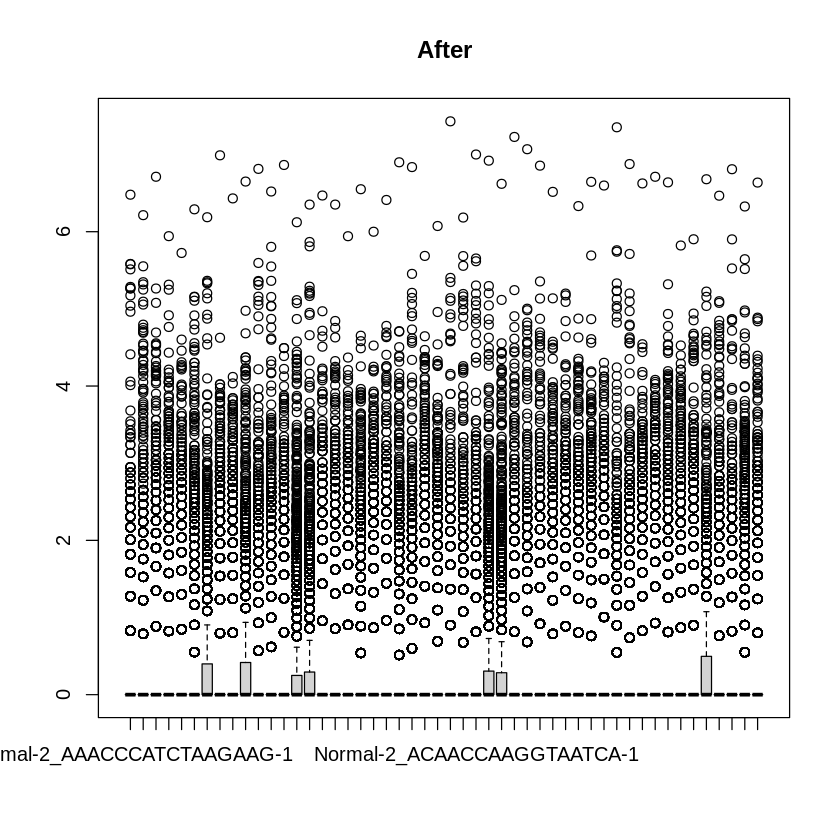

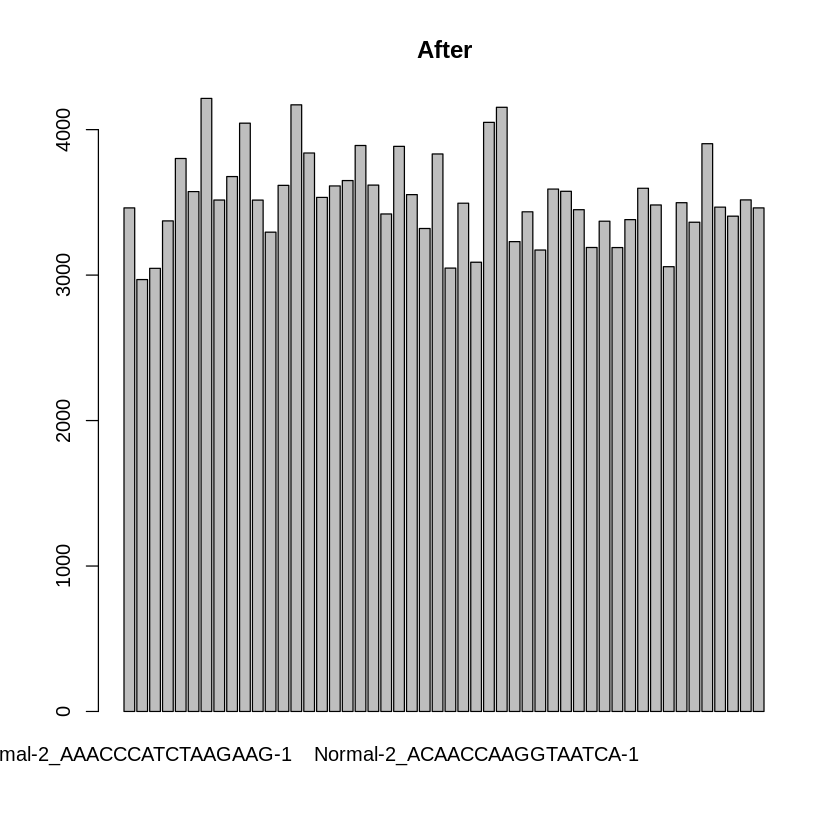

In [ ]:
boxplot((count_matrix_norm_2)[, 1:50], main = "After")
barplot(colSums(count_matrix_norm_2)[1:50], main = "After")

In [ ]:
DKDs@assays

$RNA
Assay (v5) data with 19868 features for 1525 cells
First 10 features:
 AL627309.1, AL627309.5, LINC01409, LINC01128, LINC00115, FAM41C,
LINC02593, SAMD11, NOC2L, KLHL17 
Layers:
 counts.1, counts.2, counts.3, data.1, data.2, data.3 


## 4. Highly variable features

Most genes carry little information about cell identity (housekeeping genes, genes that are off everywhere). We focus on the **2,000 most variable genes** (`vst` method), which drive the biological differences between cells. The plots show every gene (grey = not variable, red = variable) with the 10 most variable genes labelled.

In [ ]:
normals <- FindVariableFeatures(normals, selection.method = "vst", nfeatures = 2000)
top10_norms <- head(VariableFeatures(normals), 10) # the 10 most highly variable genes

DKDs <- FindVariableFeatures(DKDs, selection.method = "vst", nfeatures = 2000)
top10_DKDs <- head(VariableFeatures(DKDs), 10)

Finding variable features for layer counts.1

Finding variable features for layer counts.2

Finding variable features for layer counts.3

Finding variable features for layer counts.1

Finding variable features for layer counts.2

Finding variable features for layer counts.3

When using repel, set xnudge and ynudge to 0 for optimal results

Warning message in scale_x_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 2403 rows containing missing values or values outside the scale range
(`geom_point()`).”

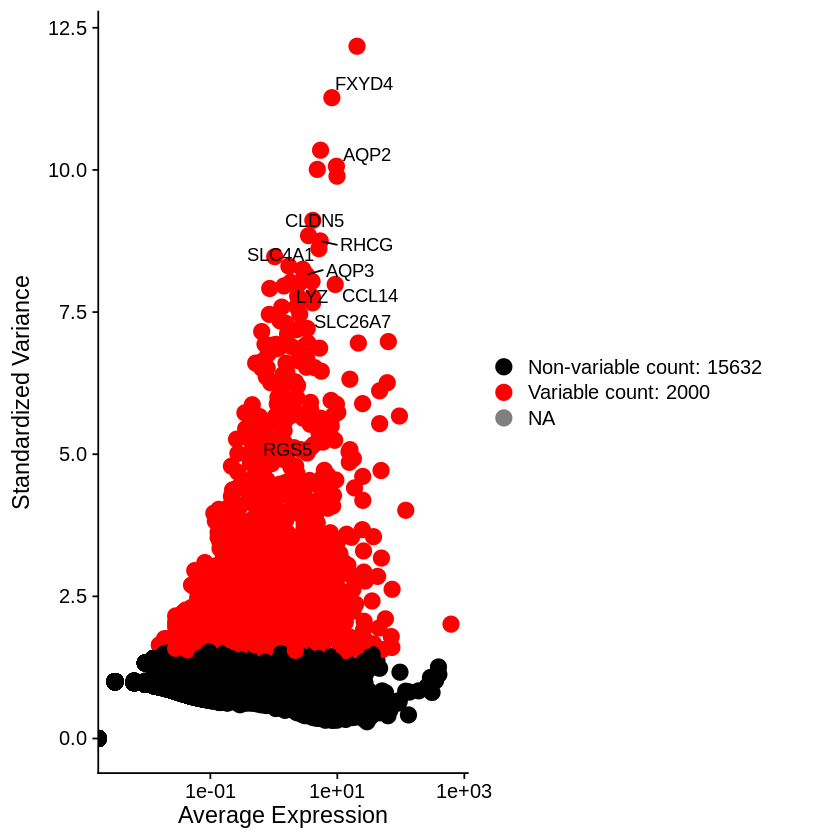

In [ ]:
plot1 <- VariableFeaturePlot(normals, pt.size = 4)
LabelPoints(plot = plot1, points = top10_norms, repel = TRUE)

When using repel, set xnudge and ynudge to 0 for optimal results

Warning message in scale_x_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 2005 rows containing missing values or values outside the scale range
(`geom_point()`).”

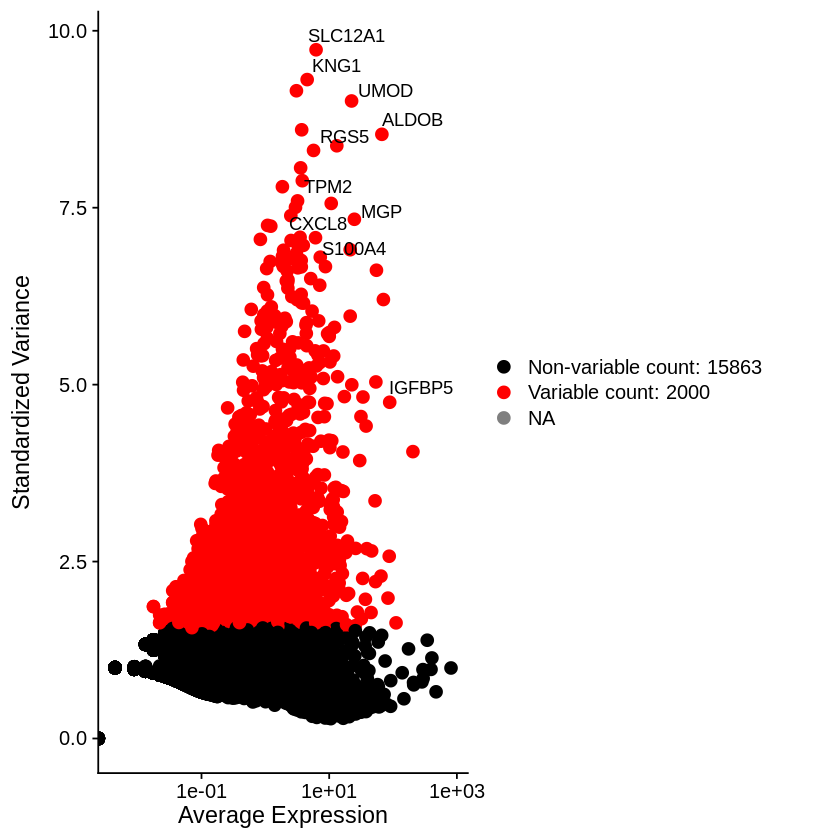

In [ ]:
plot2 <- VariableFeaturePlot(DKDs, pt.size = 3)
LabelPoints(plot = plot2, points = top10_DKDs, repel = TRUE)

## 5. Integration

Normal and DKD cells come from different samples, so technical differences (batch effects) can separate cells on the UMAP for reasons unrelated to biology. **Integration** aligns the datasets so that the same cell type from different samples clusters together.

We use Seurat's classic **CCA anchor** workflow:

1. `JoinLayers()`: merge the per-sample layers (`counts.1/2/3`, `data.1/2/3`) back into single `counts` and `data` layers; the classic workflow expects one layer per object.
2. `SelectIntegrationFeatures()`: pick genes that are variable across both datasets.
3. `FindIntegrationAnchors()`: find pairs of "mutual nearest neighbour" cells across the two datasets (anchors).
4. `IntegrateData()`: use the anchors to correct expression. This creates a new assay called **`integrated`** (2,000 genes). The original `RNA` assay is kept untouched.

### 5.1 Join layers

In [ ]:
normals_joined <- JoinLayers(normals)
DKDs_joined    <- JoinLayers(DKDs)

count_matrix_normal_joined <- GetAssayData(normals_joined, assay = "RNA", layer = "data")
count_matrix_normal_joined <- as.data.frame(as.matrix(count_matrix_normal_joined))
head(count_matrix_normal_joined)

,Normal-1_AAAGGATTCGGTAACT-1,Normal-1_AAAGTCCCAATTCACG-1,Normal-1_AACAAAGGTACAACGG-1,Normal-1_AACAACCTCATTCCTA-1,Normal-1_AACCAACAGTGATAAC-1,Normal-1_AACCAACCATAGAGGC-1,Normal-1_AACCACAAGGGATGTC-1,Normal-1_AACGTCACAAACTAGA-1,Normal-1_AAGACTCCACGCGCTA-1,Normal-1_AAGACTCCAGCTGTTA-1,⋯,Normal-3_TTGTGTTTCACCATCC-1,Normal-3_TTGTTCAGTTACCTTT-1,Normal-3_TTGTTTGCACATCATG-1,Normal-3_TTTACGTAGTGGAATT-1,Normal-3_TTTACGTGTGGTACAG-1,Normal-3_TTTCACATCATCGACA-1,Normal-3_TTTCACATCCCGAGTG-1,Normal-3_TTTCATGCACCGTACG-1,Normal-3_TTTGACTGTAGAATAC-1,Normal-3_TTTGGTTCATTCTTCA-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AL627309.1,0.0000000,0,0,0,0,0,0,0,0.0000000,0,⋯,0,0.0000000,0,0,0,0,0,0,0,0
AL627309.5,0.0000000,0,0,0,0,0,0,0,0.0000000,0,⋯,0,0.0000000,0,0,0,0,0,0,0,0
LINC01409,0.0000000,0,0,0,0,0,0,0,0.0000000,0,⋯,0,0.0000000,0,0,0,0,0,0,0,0
LINC01128,0.3766928,0,0,0,0,0,0,0,0.6664585,0,⋯,0,0.7425088,0,0,0,0,0,0,0,0
LINC00115,0.0000000,0,0,0,0,0,0,0,0.0000000,0,⋯,0,0.0000000,0,0,0,0,0,0,0,0
FAM41C,0.0000000,0,0,0,0,0,0,0,0.0000000,0,⋯,0,0.0000000,0,0,0,0,0,0,0,0


### 5.2 Find anchors and integrate

In [ ]:
intfeature <- SelectIntegrationFeatures(list(normals_joined, DKDs_joined))
head(intfeature)

[1] "RGS5"   "UMOD"   "LYZ"    "CCL14"  "IGFBP5" "CLDN5"

In [ ]:
library(future)   # parallel back-end used by Seurat

In [ ]:
Anchors <- FindIntegrationAnchors(list(normals_joined, DKDs_joined), anchor.features = intfeature)
class(Anchors)

Scaling features for provided objects

Finding all pairwise anchors

Running CCA

Merging objects

Finding neighborhoods

Finding anchors

	Found 2922 anchors

Filtering anchors

	Retained 2412 anchors

[1] "IntegrationAnchorSet"
attr(,"package")
[1] "Seurat"

About 2,400 of the 2,900 anchors survive filtering, which is plenty to align the two datasets.

In [ ]:
data <- IntegrateData(anchorset = Anchors)
data@assays

Merging dataset 1 into 2

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”

$RNA
Assay (v5) data with 21037 features for 2850 cells
Top 10 variable features:
 UMOD, RGS5, KNG1, TPM2, SLC12A1, MGP, IGFBP5, CXCL8, S100A4, ALDOB 
Layers:
 data.SeuratProject, data.scRNA_Keramati, counts.SeuratProject,
scale.data.SeuratProject, counts.scRNA_Keramati,
scale.data.scRNA_Keramati 

$integrated
Assay data with 2000 features for 2850 cells
Top 10 variable features:
 RGS5, UMOD, LYZ, CCL14, IGFBP5, CLDN5, KNG1, TAGLN, TIMP3, RBP4 


The `integrated` assay holds the batch-corrected values for the 2,000 integration features across all 2,850 cells.

In [ ]:
count_matrix_int <- GetAssayData(data, assay = "integrated", layer = "data")
count_matrix_int <- as.data.frame(as.matrix(count_matrix_int))
dim(count_matrix_int)   # genes x cells
head(count_matrix_int)

[1] 2000 2850

,Normal-1_AAAGGATTCGGTAACT-1,Normal-1_AAAGTCCCAATTCACG-1,Normal-1_AACAAAGGTACAACGG-1,Normal-1_AACAACCTCATTCCTA-1,Normal-1_AACCAACAGTGATAAC-1,Normal-1_AACCAACCATAGAGGC-1,Normal-1_AACCACAAGGGATGTC-1,Normal-1_AACGTCACAAACTAGA-1,Normal-1_AAGACTCCACGCGCTA-1,Normal-1_AAGACTCCAGCTGTTA-1,⋯,DKD-03_TTGTGGAAGCTACTAC-1,DKD-03_TTGTGTTCATCGAAGG-1,DKD-03_TTGTGTTGTGGTTTGT-1,DKD-03_TTGTTTGAGGCGAACT-1,DKD-03_TTTACCAAGGCTATCT-1,DKD-03_TTTAGTCTCAAGTCTG-1,DKD-03_TTTATGCAGGGCGAGA-1,DKD-03_TTTCATGTCCAAGCAT-1,DKD-03_TTTGACTAGGTGATAT-1,DKD-03_TTTGGAGCAACATACC-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RGS5,1.03134501,-0.02518993,-0.01715343,-0.044690666,-0.062974191,-0.05427518,-0.0542376057,-0.04290840,-0.05358359,-0.046668289,⋯,0.0000000,0,0.0000000,0.000000,0.0000000,0.0000000,0,0.0000000,3.331663,0.0000000
UMOD,0.41705319,-0.24268698,-0.22641535,-0.377148405,0.348233734,-0.25877086,1.0860391802,0.49719682,0.19756700,0.346374464,⋯,0.2885346,0,0.0000000,5.176683,0.2235342,0.3878281,0,0.5902864,0.000000,0.4712143
LYZ,0.06724599,-0.02425071,-0.03660006,-0.019957932,0.007113531,-0.03270295,-0.0003302702,-0.03213022,0.63464124,-0.008943702,⋯,0.0000000,0,0.0000000,0.000000,0.2235342,0.0000000,0,0.0000000,0.281502,0.0000000
CCL14,0.02663587,0.30297818,-0.07724228,-0.079854614,-0.054691344,-0.01325847,-0.0359696917,-0.07536409,-0.38480377,-0.045650067,⋯,0.0000000,0,0.0000000,0.000000,0.0000000,0.0000000,0,0.0000000,0.000000,0.0000000
IGFBP5,0.90092198,2.68847869,-0.31482670,-0.165534976,-0.135011110,-0.19777429,-0.5647816878,3.16781079,3.34962930,-0.199620534,⋯,0.0000000,0,4.0723874,0.000000,0.0000000,0.0000000,0,0.0000000,4.994699,0.0000000
CLDN5,2.40060034,-0.01513481,0.00000000,-0.004827306,0.000000000,0.00000000,0.0000000000,-0.01817096,-0.11785537,0.000000000,⋯,0.0000000,0,0.5885343,0.000000,0.0000000,0.0000000,0,0.0000000,1.281198,0.0000000


> **Note on the design.** Here the two integration inputs are the pooled *Normal* and the pooled *DKD* objects, so the "batch" being corrected is the condition itself. That aligns shared cell types well, but it can also absorb real disease-related differences. If your goal is to remove donor- or sample-level batch effects while keeping the disease signal, integrate by *sample* instead. The differential-expression analysis at the end uses the uncorrected `RNA` assay, so it is not affected.

## 6. Scale and center the data

`ScaleData()` turns each gene into a z-score (mean 0, variance 1 across cells). Without this, highly expressed genes would dominate PCA simply because their values are larger. The result goes into a `scale.data` layer.

In [ ]:
data_scaled <- ScaleData(data, features = rownames(data))
Layers(data_scaled, assay = "integrated")

Centering and scaling data matrix

[1] "data"       "scale.data"

In [ ]:
scaled_matrix <- GetAssayData(data_scaled, assay = "integrated", layer = "scale.data")
scaled_matrix <- as.data.frame(as.matrix(scaled_matrix))
head(scaled_matrix)

,Normal-1_AAAGGATTCGGTAACT-1,Normal-1_AAAGTCCCAATTCACG-1,Normal-1_AACAAAGGTACAACGG-1,Normal-1_AACAACCTCATTCCTA-1,Normal-1_AACCAACAGTGATAAC-1,Normal-1_AACCAACCATAGAGGC-1,Normal-1_AACCACAAGGGATGTC-1,Normal-1_AACGTCACAAACTAGA-1,Normal-1_AAGACTCCACGCGCTA-1,Normal-1_AAGACTCCAGCTGTTA-1,⋯,DKD-03_TTGTGGAAGCTACTAC-1,DKD-03_TTGTGTTCATCGAAGG-1,DKD-03_TTGTGTTGTGGTTTGT-1,DKD-03_TTGTTTGAGGCGAACT-1,DKD-03_TTTACCAAGGCTATCT-1,DKD-03_TTTAGTCTCAAGTCTG-1,DKD-03_TTTATGCAGGGCGAGA-1,DKD-03_TTTCATGTCCAAGCAT-1,DKD-03_TTTGACTAGGTGATAT-1,DKD-03_TTTGGAGCAACATACC-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
RGS5,0.81343074,-0.4383251,-0.4288036,-0.4614290,-0.4830909,-0.4727845,-0.4727400,-0.45931745,-0.4719652,-0.4637721,⋯,-0.4084807,-0.4084807,-0.4084807,-0.4084807,-0.4084807,-0.4084807,-0.4084807,-0.40848067,3.5387895,-0.4084807
UMOD,-0.16913957,-0.7430417,-0.7288872,-0.8600085,-0.2290050,-0.7570330,0.4128054,-0.09942333,-0.3600687,-0.2306224,⋯,-0.2809368,-0.5319305,-0.5319305,3.9712209,-0.3374800,-0.1945622,-0.5319305,-0.01844549,-0.5319305,-0.1220253
LYZ,-0.12577969,-0.2826013,-0.3037676,-0.2752437,-0.2288443,-0.2970881,-0.2416026,-0.29610646,0.8467126,-0.2563657,⋯,-0.2410366,-0.2410366,-0.2410366,-0.2410366,0.1420920,-0.2410366,-0.2410366,-0.24103657,0.2414464,-0.2410366
CCL14,-0.35348148,0.0458382,-0.5035873,-0.5073622,-0.4710008,-0.4111295,-0.4439477,-0.50087330,-0.9480193,-0.4579360,⋯,-0.3919708,-0.3919708,-0.3919708,-0.3919708,-0.3919708,-0.3919708,-0.3919708,-0.39197081,-0.3919708,-0.3919708
IGFBP5,-0.07299676,1.0506965,-0.8372403,-0.7433926,-0.7242047,-0.7636588,-0.9943669,1.35201413,1.4663088,-0.7648194,⋯,-0.6393340,-0.6393340,1.9206488,-0.6393340,-0.6393340,-0.6393340,-0.6393340,-0.63933404,2.5004321,-0.6393340
CLDN5,4.06242300,-0.3758736,-0.3480672,-0.3569362,-0.3480672,-0.3480672,-0.3480672,-0.38145173,-0.5645964,-0.3480672,⋯,-0.3480672,-0.3480672,0.7332143,-0.3480672,-0.3480672,-0.3480672,-0.3480672,-0.34806723,2.0058061,-0.3480672


Compare the distribution of a block of cells before (integrated values) and after scaling:

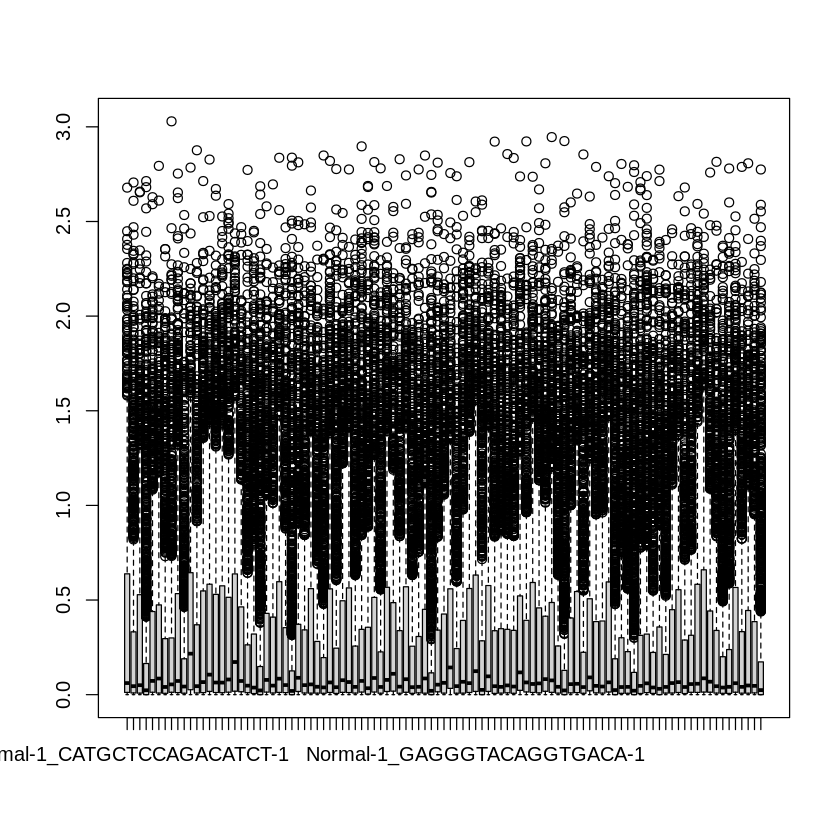

In [ ]:
boxplot(log2(abs(count_matrix_int[, 100:200]) + 1))      # integrated values

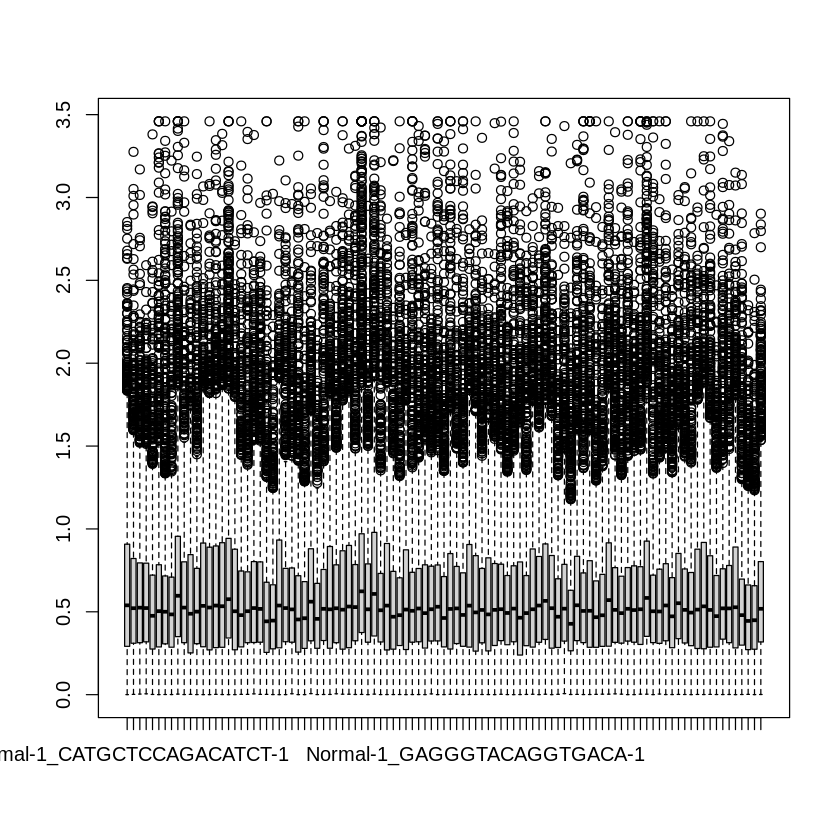

In [ ]:
boxplot(log2(abs(scaled_matrix[, 100:200]) + 1))         # scaled values

## 7. Sample metadata: condition of each cell

Cell names start with their sample (`Normal-1_...`, `DKD-02_...`), so the condition can be read off the name. We store it as `sample_type` so we can colour plots and split comparisons by condition.

In [ ]:
# text before the first "-" or "_":  "Normal-1_AAAG..." -> "Normal",  "DKD-03_TTTA..." -> "DKD"
vec <- sub("[-_].*", "", rownames(data_scaled@meta.data))
length(vec)

data_scaled[["sample_type"]] <- vec
tail(data_scaled@meta.data)
table(data_scaled$sample_type)

[1] 2850

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,sample_type
,<chr>,<dbl>,<int>,<dbl>,<chr>
DKD-03_TTTACCAAGGCTATCT-1,GSE209781,39922,5916,15.745704,DKD
DKD-03_TTTAGTCTCAAGTCTG-1,GSE209781,21107,4993,11.105321,DKD
DKD-03_TTTATGCAGGGCGAGA-1,GSE209781,34433,6398,14.637121,DKD
DKD-03_TTTCATGTCCAAGCAT-1,GSE209781,12430,4250,6.870475,DKD
DKD-03_TTTGACTAGGTGATAT-1,GSE209781,30758,6930,6.167501,DKD
DKD-03_TTTGGAGCAACATACC-1,GSE209781,16613,4723,8.288690,DKD



   DKD Normal 
  1525   1325 

## 8. Cell-cycle check

Actively dividing cells express a characteristic set of genes. If cell-cycle phase is a major source of variation it can create clusters that reflect the cell cycle instead of cell type. Seurat provides lists of S-phase and G2/M-phase genes (`cc.genes`) and `CellCycleScoring()` assigns every cell an S score, a G2M score and a phase (G1, S or G2M).

> Most of the cell-cycle genes are not among the 2,000 integrated genes, so the warning below lists many "missing" features and the score is based on the genes that are present. Section 8.3 repeats the check on the full `RNA` assay.

### 8.1 Score cells

In [ ]:
s_genes   <- cc.genes$s.genes
g2m_genes <- cc.genes$g2m.genes

data_scaled <- CellCycleScoring(data_scaled, s.features = s_genes, g2m.features = g2m_genes, set.ident = FALSE)
head(data_scaled)

Warning message:
“The following features are not present in the object: MCM5, PCNA, FEN1, MCM2, MCM4, RRM1, UNG, GINS2, MCM6, CDCA7, PRIM1, UHRF1, MLF1IP, RFC2, RPA2, NASP, SLBP, UBR7, POLD3, MSH2, RAD51, CDC45, CDC6, EXO1, TIPIN, DSCC1, BLM, CASP8AP2, USP1, POLA1, CHAF1B, BRIP1, E2F8, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: CKS1B, MKI67, TMPO, FAM64A, CKAP2L, AURKB, BUB1, ANP32E, TUBB4B, HJURP, HN1, TTK, CDC25C, RANGAP1, NCAPD2, DLGAP5, CDCA2, CDCA8, ECT2, AURKA, PSRC1, LBR, CKAP5, CTCF, NEK2, G2E3, CBX5, not searching for symbol synonyms”

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,sample_type,S.Score,G2M.Score,Phase
,<chr>,<dbl>,<int>,<dbl>,<chr>,<dbl>,<dbl>,<chr>
Normal-1_AAAGGATTCGGTAACT-1,GSE209781,21860,5092,18.559012,Normal,-0.0018472881,-0.05949818,G1
Normal-1_AAAGTCCCAATTCACG-1,GSE209781,23612,5038,19.981365,Normal,-0.0599973310,-0.03019555,G1
Normal-1_AACAAAGGTACAACGG-1,GSE209781,21160,4523,8.279773,Normal,0.0144866547,-0.04502661,S
Normal-1_AACAACCTCATTCCTA-1,GSE209781,19835,5285,15.875977,Normal,0.0127634368,-0.04920037,S
Normal-1_AACCAACAGTGATAAC-1,GSE209781,16605,4081,16.121650,Normal,0.0081711521,-0.04481752,S
Normal-1_AACCAACCATAGAGGC-1,GSE209781,23874,4416,1.415766,Normal,-0.0002772004,-0.02718068,G1
Normal-1_AACCACAAGGGATGTC-1,GSE209781,14565,4120,18.812221,Normal,-0.0431449730,-0.04534112,G1
Normal-1_AACGTCACAAACTAGA-1,GSE209781,20420,4175,19.853085,Normal,0.0256831362,-0.05159062,S
Normal-1_AAGACTCCACGCGCTA-1,GSE209781,10556,4044,4.727169,Normal,-0.0522817027,-0.07272267,G1


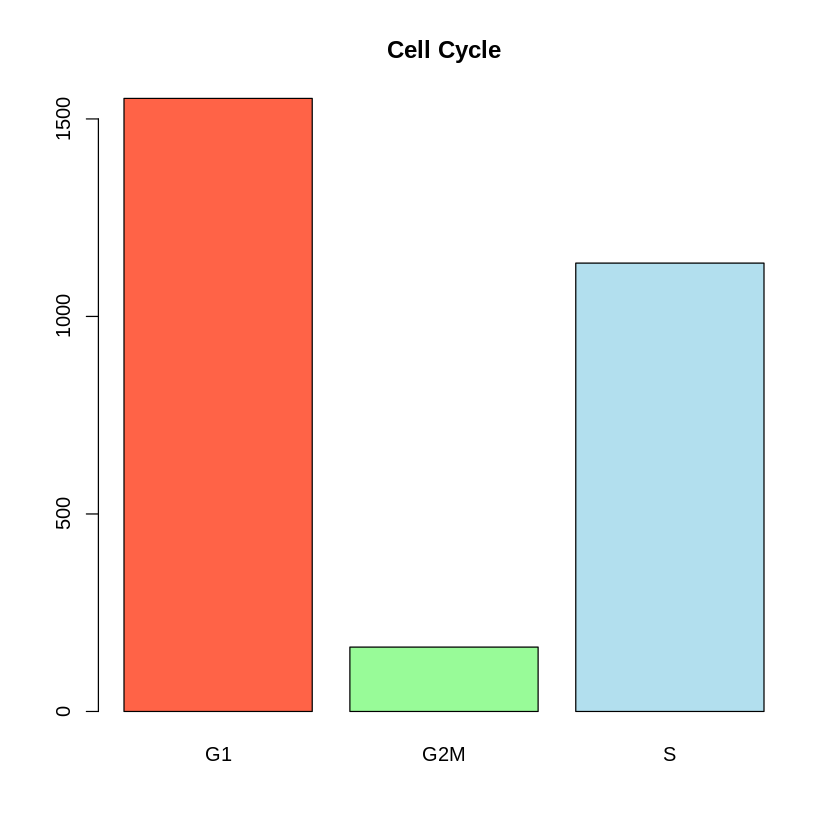

In [ ]:
barplot(table(data_scaled$Phase), main = "Cell Cycle", col = c("tomato", "palegreen", "lightblue2"))

### 8.2 Does cell cycle drive the variation?

Run a PCA using **only** the cell-cycle genes and colour it by phase. If cell-cycle phase were a strong source of variation, cells would separate by phase along the first PCs.

Here almost every cell sits in one tight group; only a few dozen cells (mostly S or G2M) spread out. Adult kidney has very few dividing cells, so cell cycle is not a major axis of variation in this data, and the condition (`sample_type`) does not separate either.

Warning message in PrepDR(object = object, features = features, verbose = verbose):
“The following 60 features requested have not been scaled (running reduction without them): MCM5, PCNA, FEN1, MCM2, MCM4, RRM1, UNG, GINS2, MCM6, CDCA7, PRIM1, UHRF1, MLF1IP, RFC2, RPA2, NASP, SLBP, UBR7, POLD3, MSH2, RAD51, CDC45, CDC6, EXO1, TIPIN, DSCC1, BLM, CASP8AP2, USP1, POLA1, CHAF1B, BRIP1, E2F8, CKS1B, MKI67, TMPO, FAM64A, CKAP2L, AURKB, BUB1, ANP32E, TUBB4B, HJURP, HN1, TTK, CDC25C, RANGAP1, NCAPD2, DLGAP5, CDCA2, CDCA8, ECT2, AURKA, PSRC1, LBR, CKAP5, CTCF, NEK2, G2E3, CBX5”
Warning message in svd.function(A = t(x = object), nv = npcs, ...):
“You're computing too large a percentage of total singular values, use a standard svd instead.”
Warning message in svd.function(A = t(x = object), nv = npcs, ...):
“did not converge--results might be invalid!; try increasing work or maxit”
Warning message:
“Requested number is larger than the number of available items (37). Setting to 37.”
Warning messag

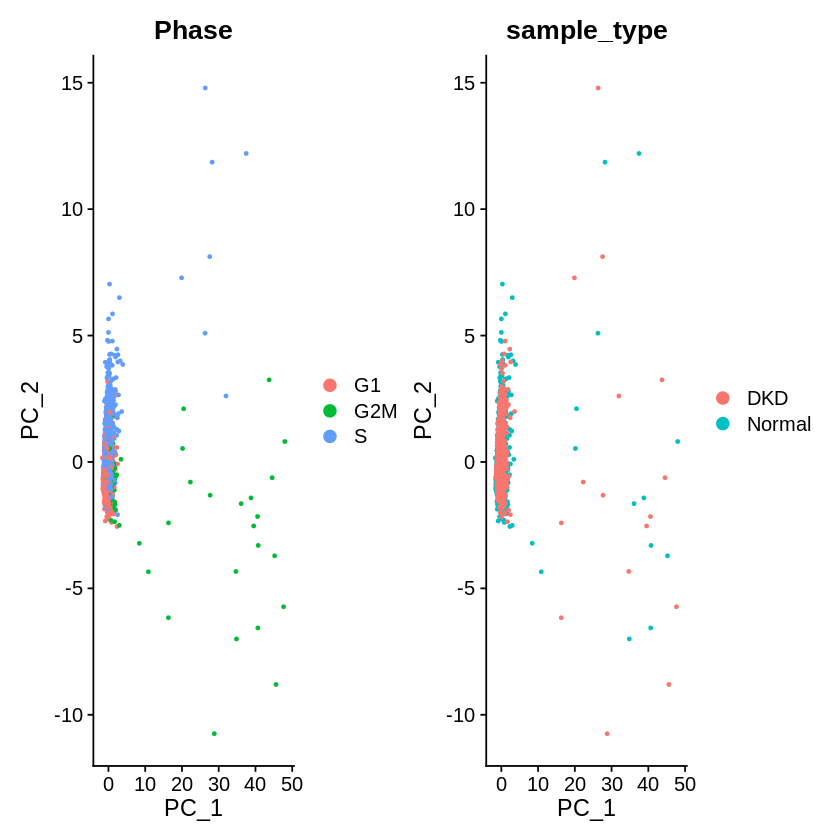

In [ ]:
data_scaled <- RunPCA(data_scaled, features = c(s_genes, g2m_genes)) # PCA using cell-cycle genes only

p1 <- DimPlot(data_scaled, group.by = "Phase")
p2 <- DimPlot(data_scaled, group.by = "sample_type")
p1 + p2

### 8.3 Check on the full RNA assay (ridge plots)

Score the joined `RNA`-assay objects, where all genes are available, and compare the expression of each cell-cycle gene across phases. Genes that are really cycling should be shifted to the right in S or G2M cells. The inline preview shows four classic genes; the full figure (all S and G2M genes, large) is saved to a PNG file.

In [ ]:
normals_joined <- CellCycleScoring(normals_joined, s.features = s_genes, g2m.features = g2m_genes, set.ident = FALSE)
DKDs_joined    <- CellCycleScoring(DKDs_joined,    s.features = s_genes, g2m.features = g2m_genes, set.ident = FALSE)

# quick inline preview
RidgePlot(normals_joined, group.by = "Phase", features = c("PCNA", "TOP2A", "MKI67", "CCNB1"), ncol = 2)

Warning message:
“The following features are not present in the object: MLF1IP, CDC45, EXO1, E2F8, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HJURP, HN1, CDC25C, DLGAP5, not searching for symbol synonyms”

In [ ]:
# full figures (all S and G2M genes), saved to files because they are very large
png(file.path(proj_dir, "ridgeplot_normals.png"), width = 2000, height = 3000)
print(RidgePlot(normals_joined, group.by = "Phase", features = c(s_genes, g2m_genes)))
dev.off()

png(file.path(proj_dir, "ridgeplot_dkds.png"), width = 2000, height = 3000)
print(RidgePlot(DKDs_joined, group.by = "Phase", features = c(s_genes, g2m_genes)))
dev.off()

### 8.4 Regression

Because the cell-cycle effect is small here, regression is not strictly necessary. It was applied anyway, so everything downstream (PCA, clusters, UMAP) is based on the regressed data. If you skip it, results will change slightly. `vars.to.regress` removes the S and G2M scores from each gene's expression.

In [ ]:
data_scaled <- ScaleData(data_scaled, vars.to.regress = c("S.Score", "G2M.Score"))

Regressing out S.Score, G2M.Score

Centering and scaling data matrix

## 9. PCA and choosing the number of dimensions

PCA compresses the 2,000 variable genes into a small number of principal components (PCs) that capture the main axes of variation. Clustering and UMAP are run on the top PCs, not on all genes, which removes noise and speeds things up.

The important choice is **how many PCs to keep**. Several tools help:

* `ElbowPlot`: variance explained per PC; look for where the curve flattens.
* `JackStraw`: a permutation test for which PCs carry real signal.
* `VizDimLoadings` and `DimHeatmap`: which genes define each PC, and whether they make biological sense.

### 9.1 Run PCA

In [ ]:
data_scaled <- RunPCA(data_scaled, features = VariableFeatures(data_scaled)) # PCA on the most variable genes

PC_ 1 
Positive:  MEIS2, ENG, A2M, RNASE1, PECAM1, TCF4, RAMP2, PTPRB, EPAS1, PCAT19 
	   EMCN, SLC9A3R2, EGFL7, GIMAP7, SLC2A3, LRRC32, CD93, ADGRL4, LMO2, IFI16 
	   PLVAP, FLT1, RAMP3, TGFBR2, THBD, CD34, SOX18, HLA-E, DLC1, HEG1 
Negative:  FXYD2, ATP1B1, TMEM176A, TMEM176B, CD24, PCSK1N, CXCL14, KRT18, KRT8, SPP1 
	   EPCAM, CAMK2N1, TSPAN1, CCDC198, EZR, SDC4, MGST1, PDZK1, MT1F, CYS1 
	   ELF3, C12orf75, PAX8, KCNJ16, SMIM24, SLC3A1, BBOX1, BICC1, SUCLG1, CMBL 
PC_ 2 
Positive:  S100A6, WFDC2, MALAT1, MAL, MUC1, ITM2C, S100A11, CD9, TACSTD2, PERP 
	   DMKN, SCNN1A, CLDN7, IER3, CLDN4, S100A2, ERBB4, ITGB6, CLDN3, EPCAM 
	   COBLL1, IGFBP7, MECOM, CDH1, KRT7, IGFBP2, DEFB1, TSPAN8, ELF3, TUBB2B 
Negative:  RBP5, DDC, MIOX, AGXT2, DPYS, AGMAT, ASS1, GATM, PAH, ALDOB 
	   KHK, GPX3, GLYAT, SLC16A9, HPD, AK4, CUBN, PRAP1, MSRA, FMO1 
	   BHMT, ACY1, PEPD, GPD1, GLYATL1, FBP1, FABP1, SLC13A3, GSTA1, SLC22A8 
PC_ 3 
Positive:  VIM, PALLD, TPM1, ZEB2, SPON2, CALD1, CDH6, INHBA, TNC, IL

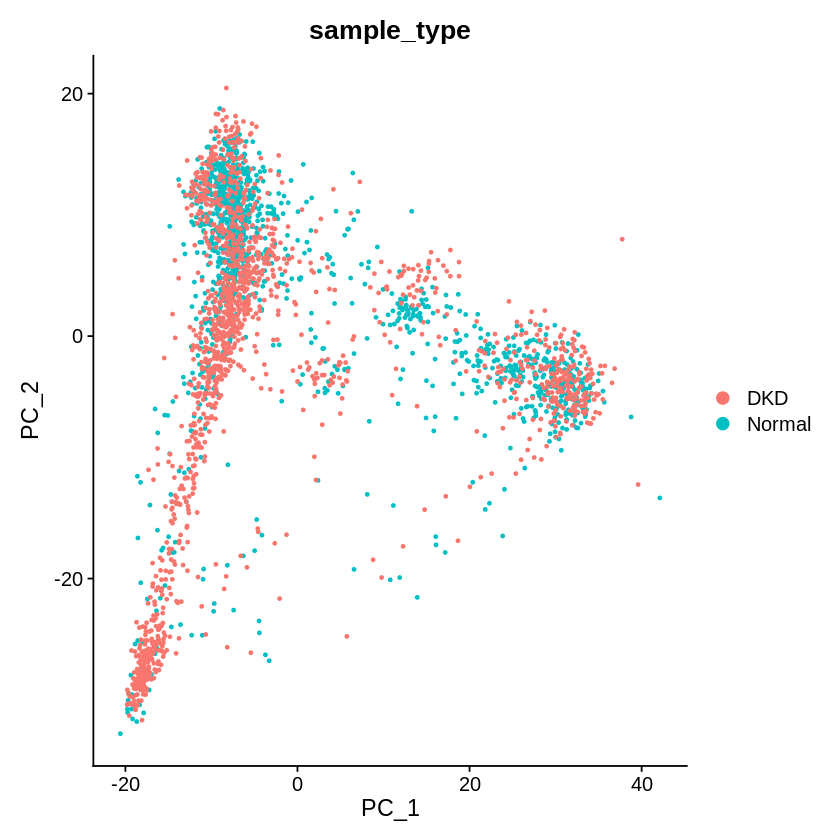

In [ ]:
DimPlot(data_scaled, reduction = "pca", group.by = "sample_type")

### 9.2 How many PCs?

Warning message:
“Removed 26600 rows containing missing values or values outside the scale range
(`geom_point()`).”

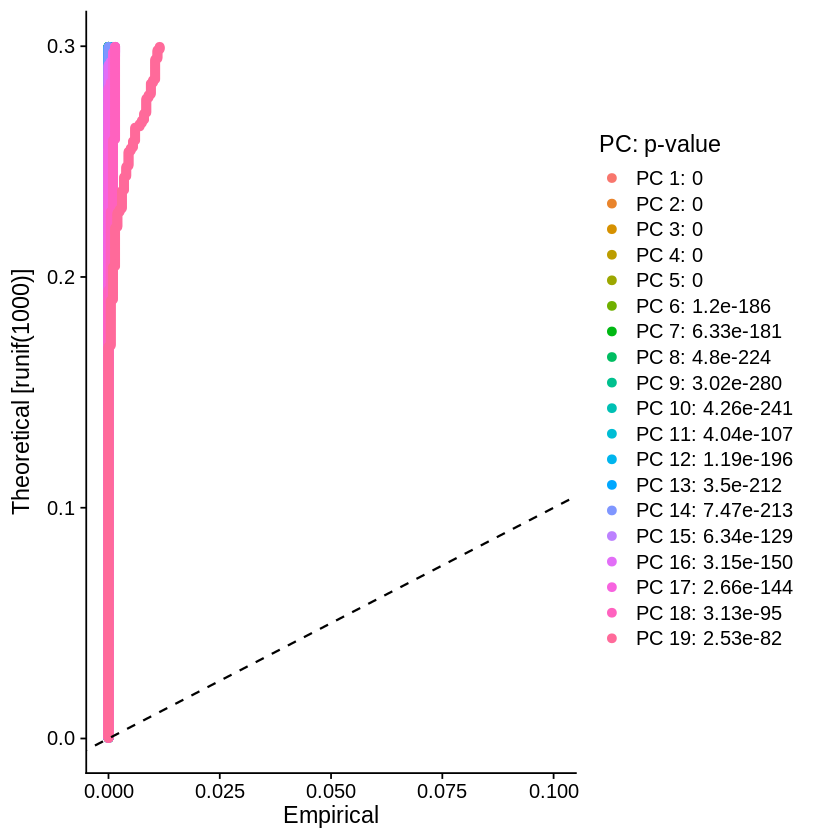

In [ ]:
data_scaled <- JackStraw(data_scaled)
data_scaled <- ScoreJackStraw(data_scaled, dims = 1:19)
JackStrawPlot(data_scaled, dims = 1:19)

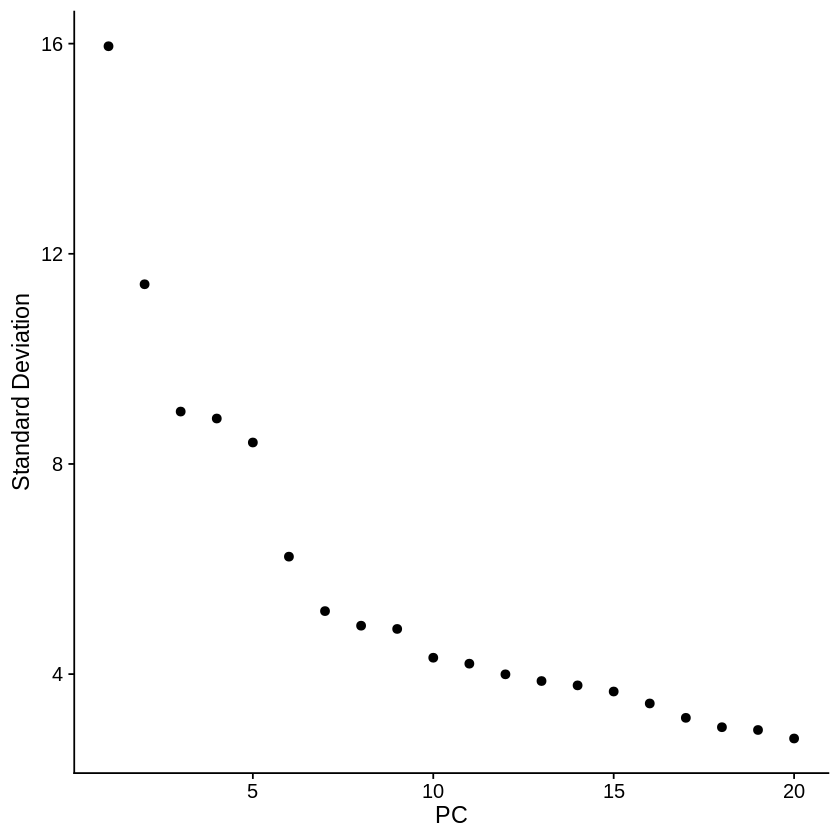

In [ ]:
ElbowPlot(data_scaled)

The standard deviation drops steeply up to about PC 6 to 7 and then flattens gradually; there is no single sharp elbow. We therefore use **20 PCs**, a conservative choice that keeps the weaker but still real signals.

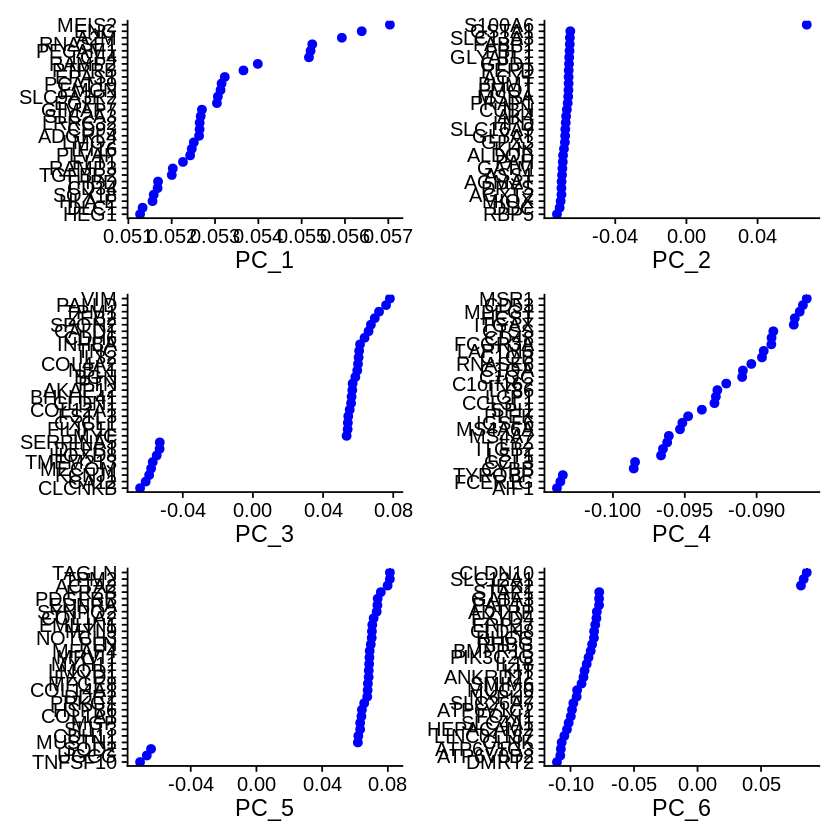

In [ ]:
VizDimLoadings(data_scaled, dims = 1:6)

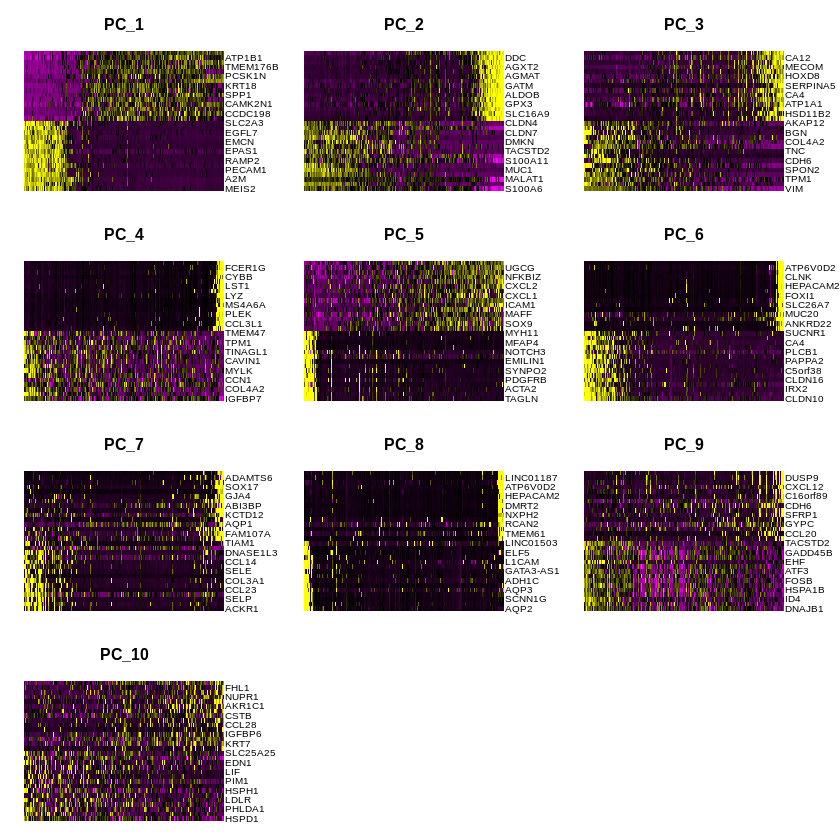

In [ ]:
DimHeatmap(data_scaled, dims = 1:10)

**Too few vs too many PCs**

* *Too few PCs*: distinct cell types merge, marker genes get mixed and known biology is lost (e.g. CD4 and CD8 T cells collapse into one T-cell cluster).
* *Too many PCs*: tiny unstable clusters appear, marker genes become weak or inconsistent, and clusters are driven by mitochondrial percentage, cell-cycle phase or sequencing depth. Small parameter changes then give different clusterings.

**A practical workflow for a new dataset**

1. Run PCA and inspect the elbow plot.
2. Look at the gene loadings of the first 20 to 30 PCs.
3. Start with a reasonable range (20 to 30 PCs is common for scRNA-seq).
4. Cluster at several resolutions.
5. Compare the biological conclusions across nearby choices (for example 20 vs 30 PCs and resolution 0.6 vs 0.8).
6. Choose the simplest combination that captures the expected biology without unsupported subdivisions.

## 10. Clustering, t-SNE and UMAP

### 10.1 Neighbour graph and clusters

Clustering works in two steps:

1. `FindNeighbors()` builds a k-nearest-neighbour graph between cells using the first 20 PCs, then refines it into a shared-nearest-neighbour (SNN) graph.
2. `FindClusters()` finds communities in that graph (Louvain algorithm). The **resolution** parameter controls granularity: higher gives more, smaller clusters.

We compute three resolutions (0.5, 0.8, 1) so they can be compared. **0.8 is run last so that it becomes the active clustering** (`seurat_clusters` and the cell identities), which is what the rest of the notebook uses.

In [ ]:
data_scaled <- FindNeighbors(data_scaled, dims = 1:20)

Computing nearest neighbor graph

Computing SNN

In [ ]:
data_scaled <- FindClusters(data_scaled, resolution = c(0.5, 1), verbose = FALSE)
data_scaled <- FindClusters(data_scaled, resolution = 0.8)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2850
Number of edges: 88827

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8915
Number of communities: 17
Elapsed time: 0 seconds

In [ ]:
# number of clusters at each resolution
length(unique(data_scaled$`integrated_snn_res.0.5`))
length(unique(data_scaled$`integrated_snn_res.0.8`))
length(unique(data_scaled$`integrated_snn_res.1`))

[1] 13

[1] 17

[1] 18

### 10.2 t-SNE and UMAP

Both methods squeeze the 20 PCs into two dimensions for visualization. UMAP usually preserves more of the global structure and is the standard choice; t-SNE is shown for comparison. **These plots are for looking, not for analysis**: distances between far-apart groups on a UMAP should not be over-interpreted.

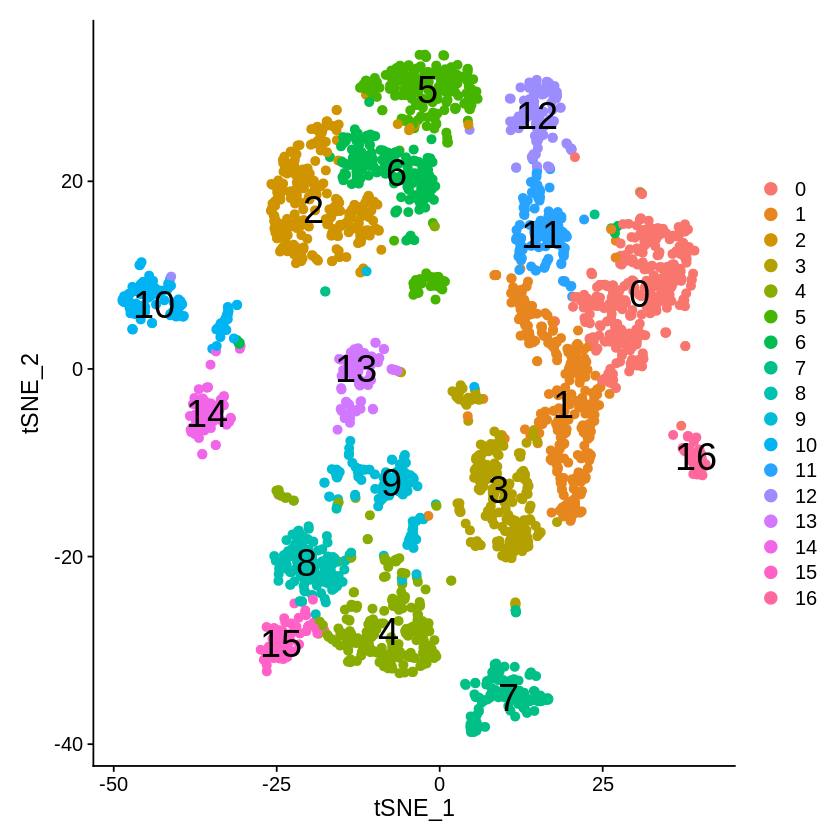

In [ ]:
data_scaled <- RunTSNE(data_scaled, dims = 1:20)
DimPlot(data_scaled, reduction = "tsne", label = TRUE, pt.size = 2, label.size = 8)

In [ ]:
data_scaled <- RunUMAP(data_scaled, dims = 1:20)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
15:41:36 UMAP embedding parameters a = 0.9922 b = 1.112

15:41:36 Read 2850 rows and found 20 numeric columns

15:41:36 Using Annoy for neighbor search, n_neighbors = 30

15:41:36 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

**************************************************
|

15:41:37 Writing NN index file to temp file /tmp/RtmptQzdeE/file5ce6f072c1a

15:41:37 Searching Annoy index using 1 thread, search_k = 3000

15:41:38 Annoy recall = 100%

15:41:41 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

15:41:45 Initializing from normalized Laplaci

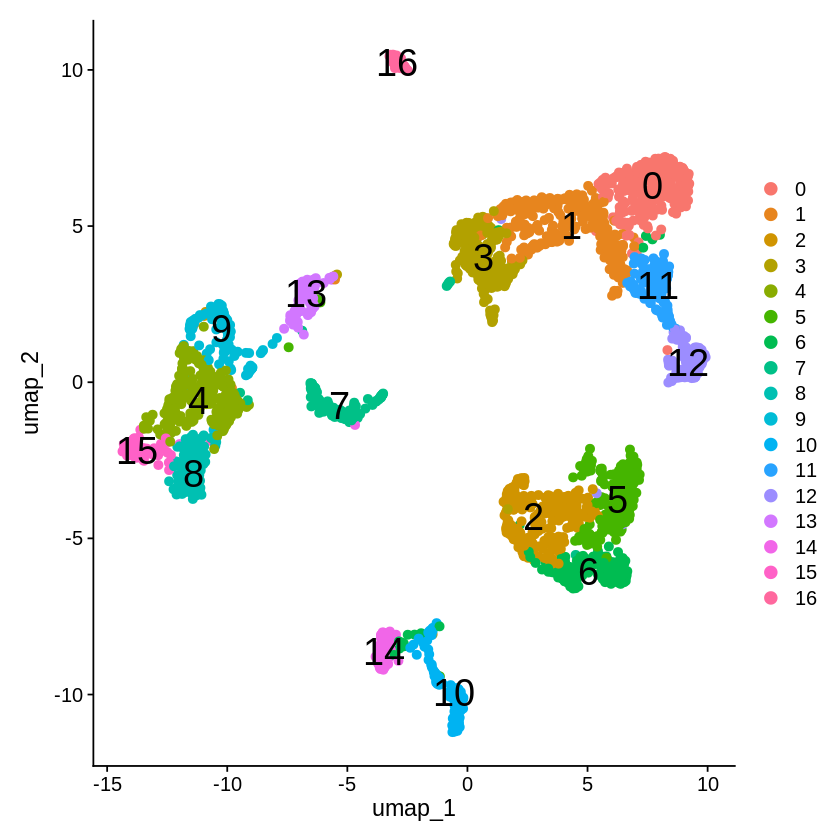

In [ ]:
DimPlot(data_scaled, reduction = "umap", label = TRUE, pt.size = 2, label.size = 8)

### 10.3 Choosing the resolution

Look at the same UMAP coloured by each resolution:

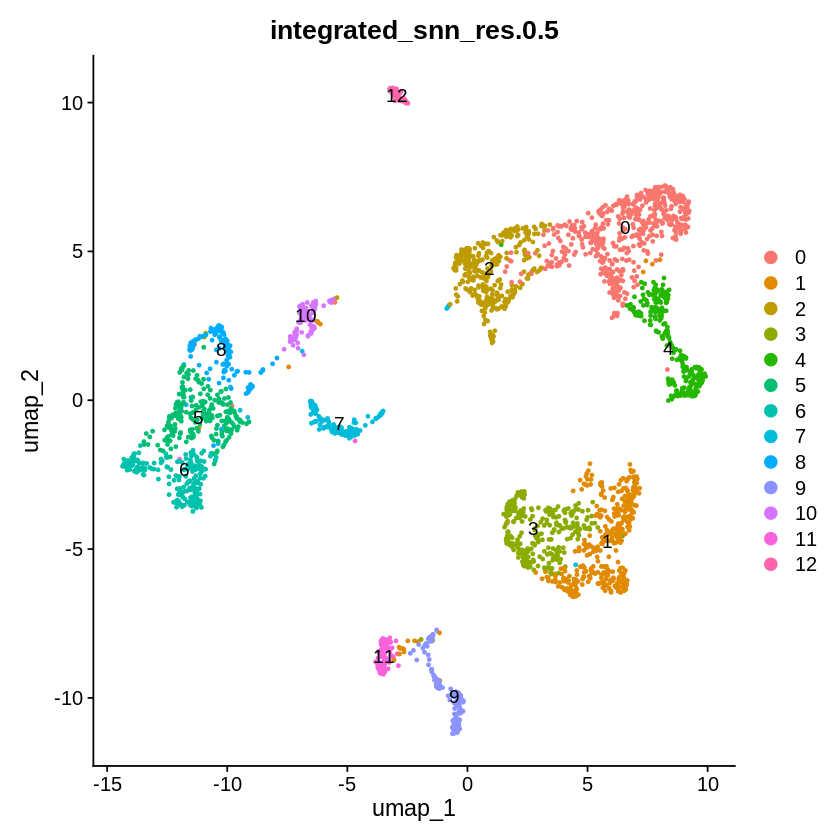

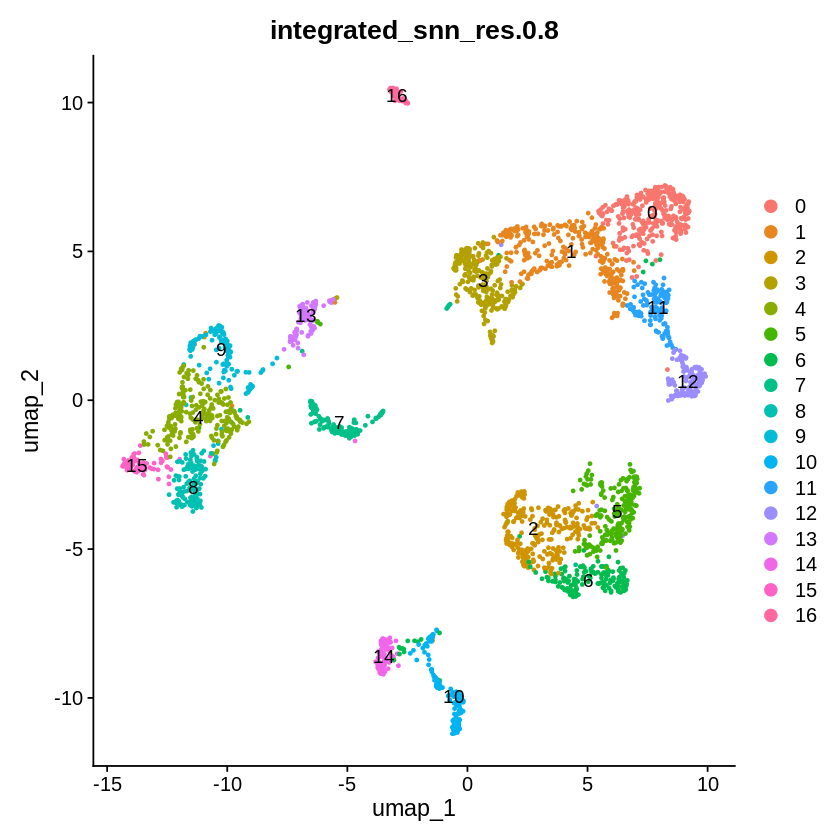

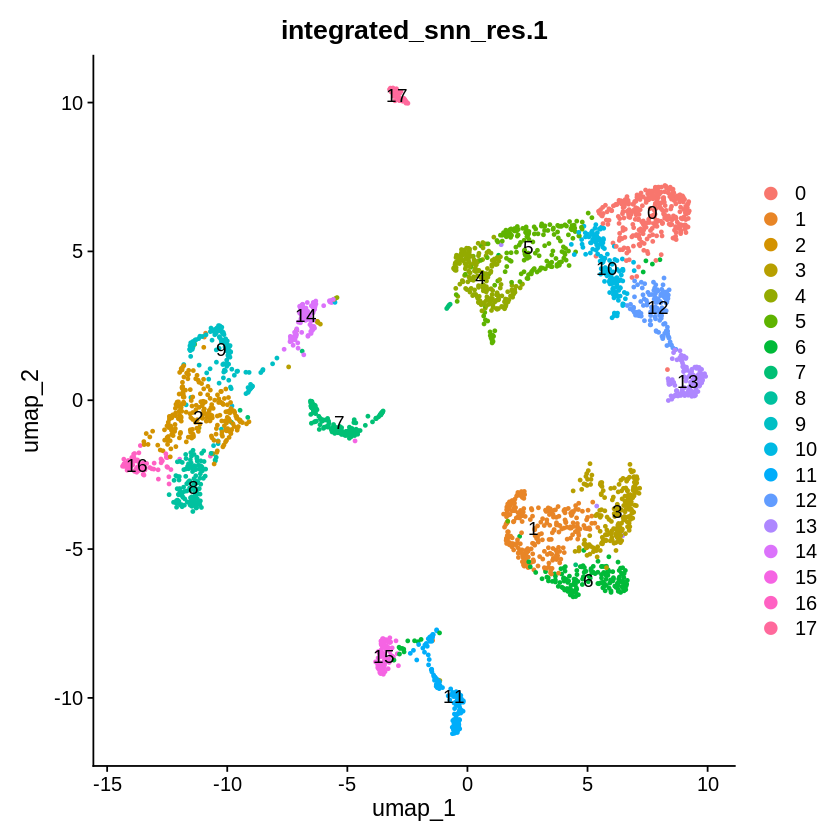

In [ ]:
DimPlot(data_scaled, label = TRUE, group.by = "integrated_snn_res.0.5")
DimPlot(data_scaled, label = TRUE, group.by = "integrated_snn_res.0.8")
DimPlot(data_scaled, label = TRUE, group.by = "integrated_snn_res.1")

A **clustree** puts all resolutions in one picture. Each row is a resolution, each circle a cluster (size = number of cells), and the arrows show where the cells of a cluster go when the resolution is increased (darker arrow = larger share of cells).

Loading required package: ggraph

Loading required package: ggplot2


Attaching package: ‘ggraph’


The following object is masked from ‘package:sp’:

    geometry

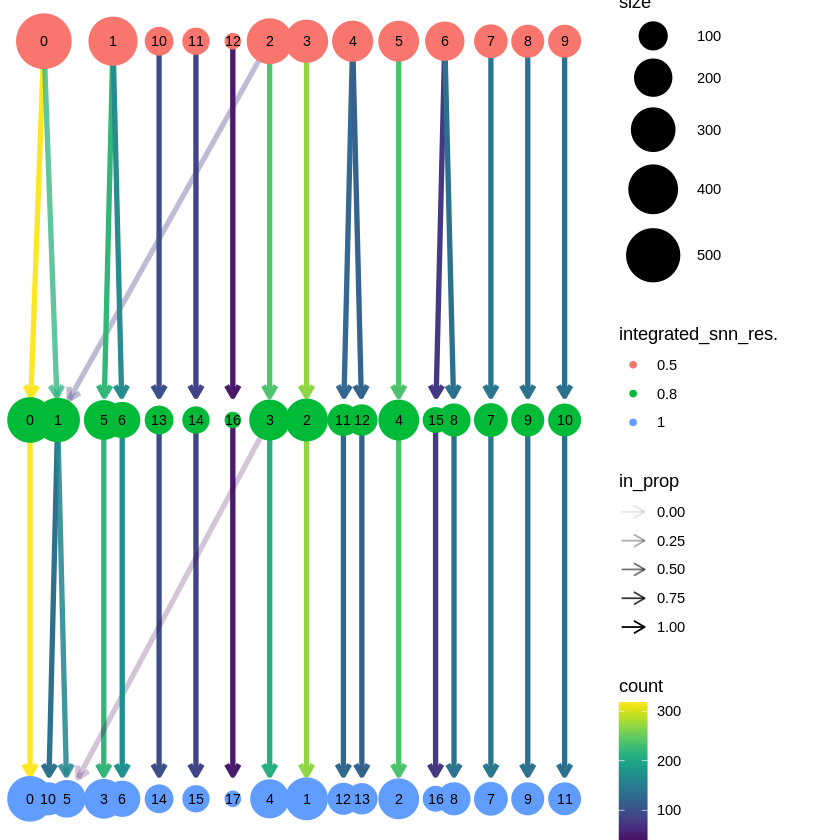

In [ ]:
library(clustree)
clustree(data_scaled@meta.data, prefix = "integrated_snn_res.")

In this dataset most clusters pass unchanged from 0.5 to 0.8 to 1 and only a handful split, so the result is not very sensitive to the resolution. We use **0.8 (17 clusters)**.

**How to read a clustree**

* A cluster that keeps splitting into meaningful sub-clusters with stable relationships may reflect real biological heterogeneity.
* Many tiny, unstable groups suggest over-clustering.
* A clustree is a guide, not a judge. The real question is: *do the new clusters have distinct marker genes?* If yes, the split is probably meaningful; if no, a lower resolution is better.

**Recommended workflow**

1. Cluster at several resolutions.
2. Check the clustree for stable vs excessive splitting.
3. Look at each clustering on the UMAP.
4. Find marker genes for the new clusters and ask: are they biologically coherent, and do the clusters match known cell types or plausible states?
5. If a new cluster has no unique markers and looks driven by noise (low-quality cells, cell-cycle genes), go back to a lower resolution.

### 10.4 The chosen clustering by condition and sample type

Left to right: cell-cycle phase, condition and cluster on the same UMAP.

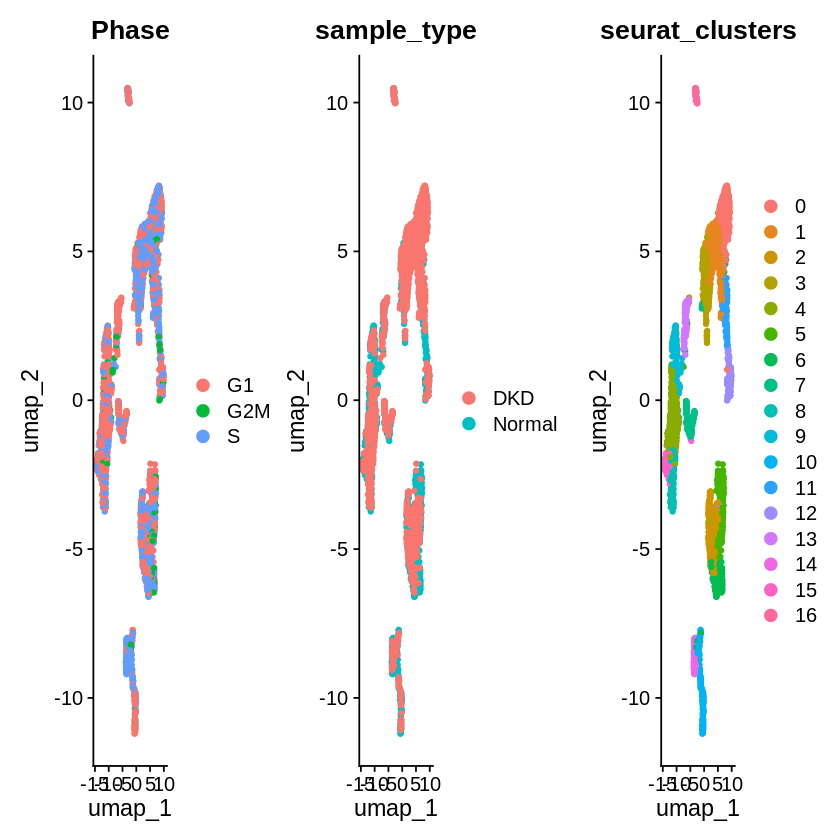

In [ ]:
p1 <- DimPlot(data_scaled, reduction = "umap", pt.size = 1, label.size = 4, group.by = "Phase")
p2 <- DimPlot(data_scaled, reduction = "umap", pt.size = 1, label.size = 4, group.by = "sample_type")
p3 <- DimPlot(data_scaled, reduction = "umap", pt.size = 1, label.size = 4, group.by = "seurat_clusters")
p1 + p2 + p3

How many cells does each cluster get from each condition? Clusters dominated by one condition are either disease-specific states or the result of residual batch effects, and are worth checking against the markers.

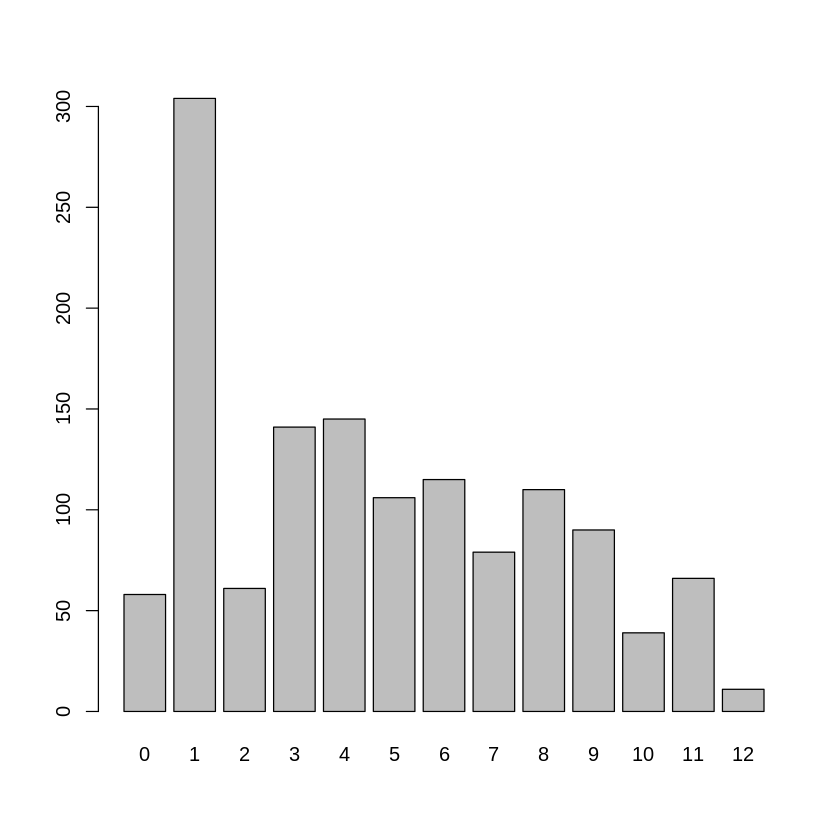

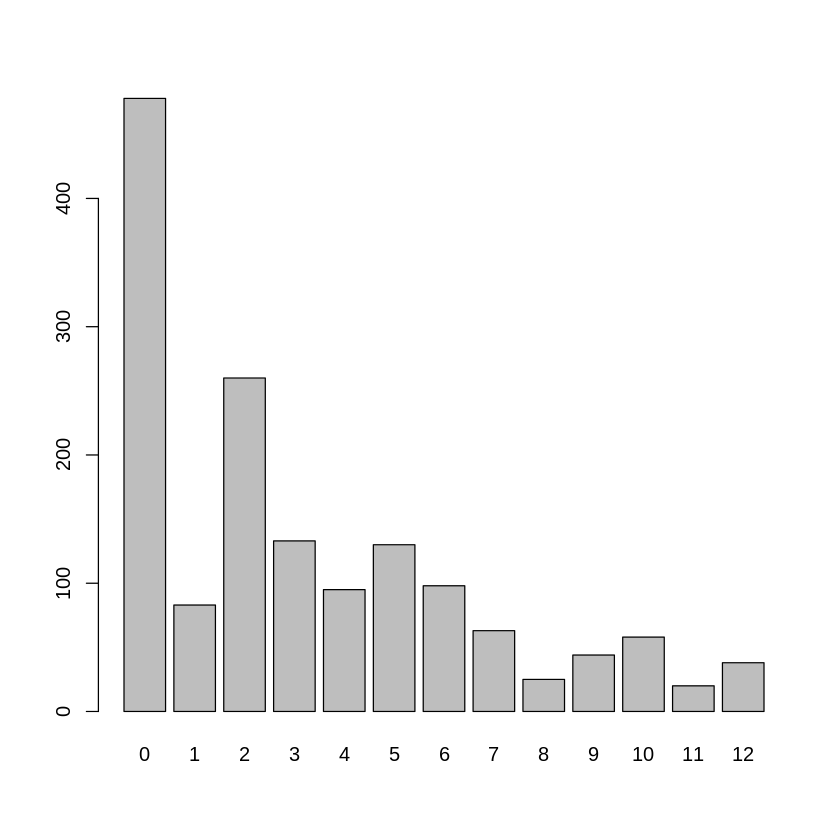

In [ ]:
norm_sub <- subset(data_scaled@meta.data, data_scaled@meta.data$sample_type == "Normal")
dkd_sub  <- subset(data_scaled@meta.data, data_scaled@meta.data$sample_type == "DKD")

barplot(table(norm_sub$seurat_clusters))   # Normal cells per cluster
barplot(table(dkd_sub$seurat_clusters))    # DKD cells per cluster

## 11. Marker genes

**What is the purpose of marker identification?** After clustering, Seurat has given you groups of cells, but the cluster numbers have no biological meaning: cluster 0 is not "T cells" and cluster 1 is not "B cells". They are just groups of cells with similar expression profiles. The question now is *which genes distinguish each cluster from all the others?* Those genes are the **marker genes**.

| Cluster | Top marker genes | Interpretation |
| --- | --- | --- |
| Cluster 1 | CD3D, CD3E, IL7R | CD4 T cells |
| Cluster 2 | CD79A, MS4A1, CD37 | B cells |
| Cluster 3 | LST1, S100A8, LILRB1 | Myeloid cells |

A marker gene can describe different biological dimensions of a cell. For cell-type annotation the **identity** markers matter most; **state** and **quality** genes are different things to keep apart.

```text
                 CELL
                  |
       +----------+----------+
       |          |          |
   Identity      State      Quality
       |          |          |
     CD3D       MKI67      MT-ND1
     MS4A1      IFNG       RPLP0
     LST1       FOS
```

### 11.1 Find markers for every cluster

`FindAllMarkers()` compares each cluster with all other cells (Wilcoxon rank-sum test by default). Settings used:

* `only.pos = TRUE`: report only genes **higher** in the cluster.
* `min.pct = 0.1`: the gene must be detected in at least 10% of cells of either group.
* `logfc.threshold = 0.25`: minimum average log2 fold-change.

> The run takes a few minutes. Installing the `presto` package (`devtools::install_github("immunogenomics/presto")`) makes the Wilcoxon test much faster.
>
> **Caveat.** This was run on the *active* assay, which is `integrated`. Seurat recommends testing for marker genes on the uncorrected `RNA` assay (`DefaultAssay(obj) <- "RNA"`), because batch-corrected values are not true expression levels. Some of the top hits below (for example TNMD and CCL20 for cluster 0, detected in many cells of other clusters too) look unexpected for kidney tubule, so repeating this step on the `RNA` assay and comparing is a worthwhile check.

In [ ]:
suppressPackageStartupMessages(library(dplyr))

markers <- FindAllMarkers(
    data_scaled,
    only.pos = TRUE,
    min.pct = 0.1,
    logfc.threshold = 0.25
)

Calculating cluster 0

For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session

Calculating cluster 1

Calculating cluster 2

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 3

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 4

Calculating cluster 5

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 6

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Calculating cluster 7

### 11.2 How many markers per cluster?

Does every cluster have a reasonable number of markers? A cluster with almost none needs investigation (very small, low quality, or over-split). The bar plot below counts only significant, positive markers (`p_val_adj < 0.05` and `avg_log2FC > 0.25`).

In [ ]:
table(markers$cluster)


  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16 
347 341 335 265 758 478 366 581 596 766 341 355 315 441 341 632 314 

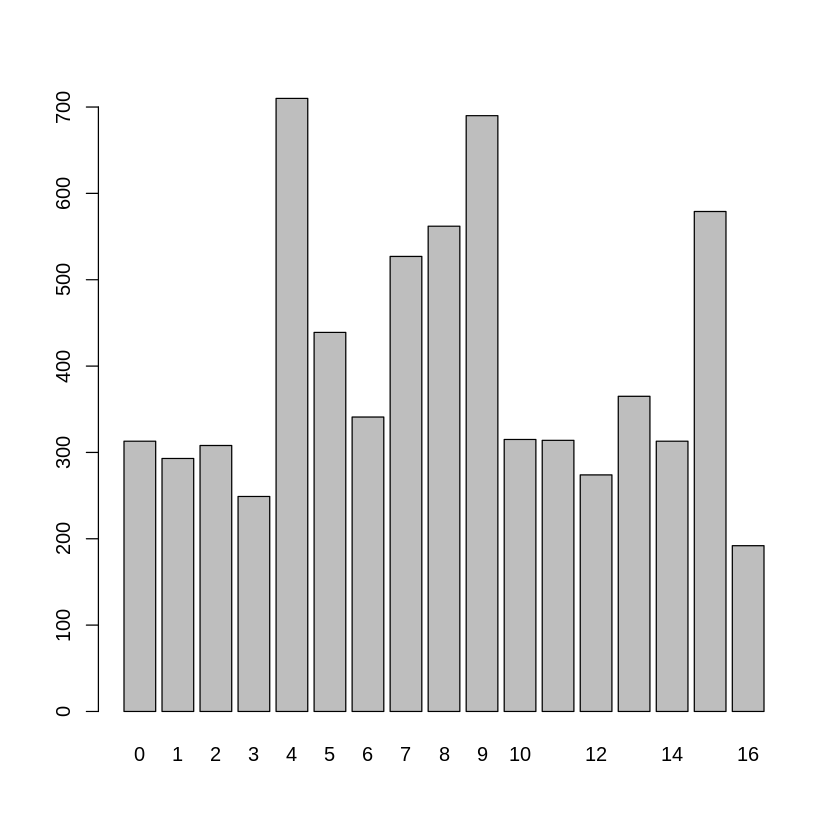

In [ ]:
markers_filtered <- subset(markers, p_val_adj < 0.05 & avg_log2FC > 0.25)
barplot(table(markers_filtered$cluster))

### 11.3 Top markers per cluster

Instead of reading hundreds of genes, take the top 10 per cluster by fold-change.

In [ ]:
top_markers <- markers %>%
    group_by(cluster) %>%
    slice_max(avg_log2FC, n = 10)

head(top_markers)

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0.000000e+00,5.733875,0.465,0.296,0.000000e+00,0,TNMD
0.000000e+00,5.413050,0.645,0.479,0.000000e+00,0,CCL20
0.000000e+00,4.715210,0.487,0.420,0.000000e+00,0,TAC1
2.220446e-16,4.629112,0.324,0.199,4.440892e-13,0,SAA1
0.000000e+00,4.363808,0.509,0.411,0.000000e+00,0,LTF
5.062617e-14,3.907745,0.443,0.359,1.012523e-10,0,TNFAIP6


### 11.4 Heatmap of the top markers

A heatmap shows at a glance whether each cluster has its own block of genes. With many clusters use only 5 to 10 genes per cluster; plotting hundreds of genes at once is slow and can crash the session.

In [ ]:
top5 <- markers %>%
    group_by(cluster) %>%
    slice_max(avg_log2FC, n = 5)

options(repr.plot.width = 14, repr.plot.height = 10)
DoHeatmap(data_scaled, features = top5$gene, size = 3)
options(repr.plot.width = 7, repr.plot.height = 7)

### 11.5 Canonical marker panel (dot plot)

This is where biological knowledge enters. A dot plot shows, per cluster, the **percentage of cells expressing** a gene (dot size) and its **average expression** (colour). The first panel below is a generic immune panel (T, B, NK, myeloid, dendritic cells); kidney-specific markers are used in section 12.

Two things to notice: the plot shows only genes that exist in the active (`integrated`, 2,000-gene) assay, so MS4A1, CD79A, FCER1A and CLEC10A are missing (hence the empty `NA` column), and cluster 9 stands out for T/NK genes (CD3D, CD3E, NKG7, GNLY) while cluster 13 stands out for myeloid genes (LYZ, S100A8).

Warning message:
“Could not find MS4A1 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find CD79A in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find FCER1A in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find CLEC10A in the default search locations, found in ‘RNA’ assay instead”

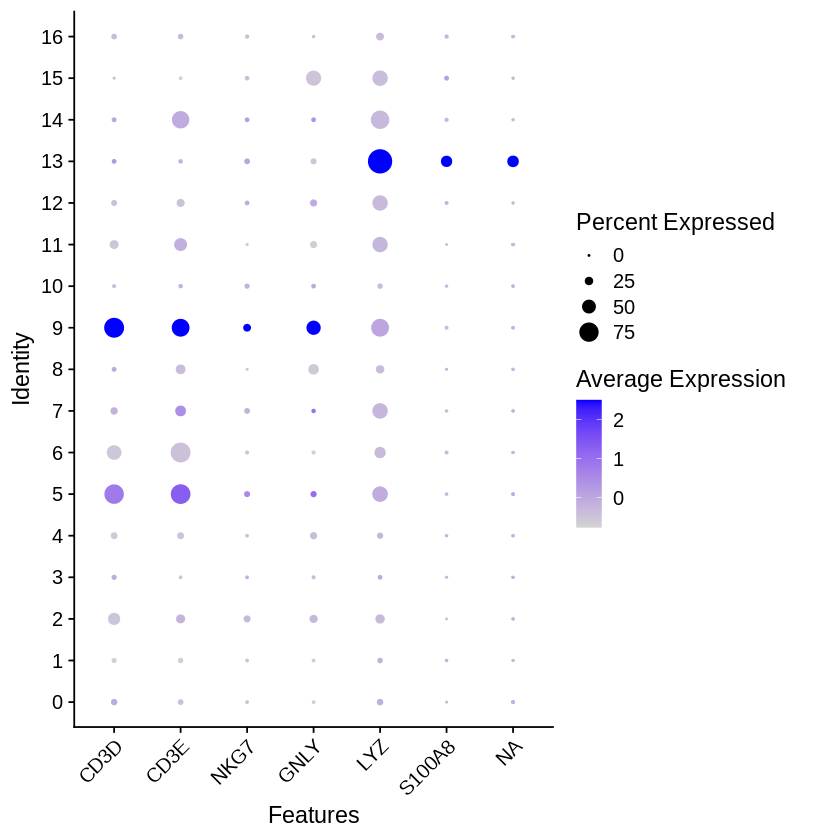

In [ ]:
marker_panel <- c(
    "CD3D", "CD3E",       # T
    "MS4A1", "CD79A",     # B
    "NKG7", "GNLY",       # NK
    "LYZ", "S100A8",      # myeloid
    "FCER1A", "CLEC10A"   # DC
)

DotPlot(data_scaled, features = marker_panel) + RotatedAxis()

### 11.6 From markers to labels

1. Keep the full marker table (done).
2. Check marker counts per cluster (done).
3. Look at top markers and a heatmap (done).
4. Use a canonical marker panel (dot plot) to give each cluster a **provisional identity**, for example *cluster 0 -> proximal tubule, cluster 1 -> B cell, cluster 2 -> monocyte, ...*
5. Validate with `FeaturePlot` / `VlnPlot` of the key genes.
6. If convincing, annotate; if questionable, revisit the clustering.

```text
                  FindAllMarkers
                       |
                       v
              Full marker table
                       |
          +------------+------------+
          v                         v
   Statistical QC              Top markers
          |                         |
          |                         v
          |                   Heatmap / table
          |                         |
          +------------+------------+
                       v
                Canonical markers
                       |
                       v
                    DotPlot
                       |
                       v
                Provisional labels
                       |
                       v
              FeaturePlot / VlnPlot
                       |
                       v
               Biological validation
                       |
              +--------+--------+
              v                 v
        convincing          questionable
              |                 |
              v                 v
          annotate        revisit clustering
```

## 12. Cell-type annotation

Annotation turns cluster numbers into cell types. There is no single best method, so three complementary approaches are used here and compared in section 13.

| Method | How it works | Strength | Weakness |
| --- | --- | --- | --- |
| **12.1 SingleR** | compares each cell with a labelled reference (Human Primary Cell Atlas) | fast, automatic, one label per cell | generic reference with few kidney cell types |
| **12.2 Marker-based** | you assign clusters from known marker genes (literature, CellMarker) | uses expert knowledge, works for any tissue | manual, subjective, slow |
| **12.3 Reference mapping** | transfers labels from an annotated kidney scRNA-seq atlas (Stewart et al. demo from Azimuth) | tissue-specific, gives a confidence score | depends on how similar the reference is to your data |

> **General caveat.** Automated annotation cannot reliably discover cell types that are *outside the vocabulary of its reference*. It will always return the closest label it knows, even if that label is biologically wrong.

All cluster-level steps use the clustering at resolution 0.8 (`seurat_clusters`), the same one the markers were computed on.

### 12.1 SingleR with the Human Primary Cell Atlas

`SingleR` correlates each cell's expression profile with every labelled sample in a reference and assigns the best match, **cell by cell** (no clustering needed). Here the reference is `HumanPrimaryCellAtlasData()` from the `celldex` package, using its main labels (`label.main`).

In [ ]:
suppressPackageStartupMessages({
  library(SingleR)
  library(celldex)
  library(SingleCellExperiment)
})

ref <- celldex::HumanPrimaryCellAtlasData(ensembl = FALSE)   # downloaded on first use
object.size(ref)

111806304 bytes

In [ ]:
head(unique(as.data.frame(ref$label.main)))   # the vocabulary SingleR can choose from

,ref$label.main
,<chr>
1,DC
13,Smooth_muscle_cells
19,Epithelial_cells
29,B_cell
33,Neutrophils
36,T_cells


Join the RNA layers of the integrated object once more (one `counts` and one `data` layer) and run SingleR on it. This new object, `data_scaled_joined`, is the one that carries all annotations from here on.

In [ ]:
data_scaled_joined <- JoinLayers(data_scaled, assay = "RNA")

labs <- SingleR(test = as.SingleCellExperiment(data_scaled_joined), ref = ref, labels = ref$label.main)
table(labs$labels)


              B_cell         Chondrocytes                  CMP 
                   1                   10                    1 
                  DC Embryonic_stem_cells    Endothelial_cells 
                   6                    3                  568 
    Epithelial_cells          Fibroblasts                  GMP 
                1133                   14                    5 
         Hepatocytes            iPS_cells           Macrophage 
                 834                    5                   50 
            Monocyte                  MSC Neuroepithelial_cell 
                  40                    4                    2 
             Neurons              NK_cell          Osteoblasts 
                   1                    6                   14 
 Smooth_muscle_cells              T_cells    Tissue_stem_cells 
                  49                    5                   99 

In [ ]:
data_scaled_joined$CellTypes <- labs$labels
head(data_scaled_joined@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,sample_type,S.Score,G2M.Score,Phase,integrated_snn_res.1,seurat_clusters,integrated_snn_res.0.5,name,integrated_snn_res.0.8,CellTypes
,<chr>,<dbl>,<int>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>,<chr>
Normal-1_AAAGGATTCGGTAACT-1,GSE209781,21860,5092,18.559012,Normal,-0.0018472881,-0.05949818,G1,9,9,8,9,9,Endothelial_cells
Normal-1_AAAGTCCCAATTCACG-1,GSE209781,23612,5038,19.981365,Normal,-0.0599973310,-0.03019555,G1,11,10,9,10,10,Epithelial_cells
Normal-1_AACAAAGGTACAACGG-1,GSE209781,21160,4523,8.279773,Normal,0.0144866547,-0.04502661,S,5,3,2,3,3,Hepatocytes
Normal-1_AACAACCTCATTCCTA-1,GSE209781,19835,5285,15.875977,Normal,0.0127634368,-0.04920037,S,11,10,9,10,10,Epithelial_cells
Normal-1_AACCAACAGTGATAAC-1,GSE209781,16605,4081,16.121650,Normal,0.0081711521,-0.04481752,S,0,0,0,0,0,Hepatocytes
Normal-1_AACCAACCATAGAGGC-1,GSE209781,23874,4416,1.415766,Normal,-0.0002772004,-0.02718068,G1,4,3,2,3,3,Hepatocytes


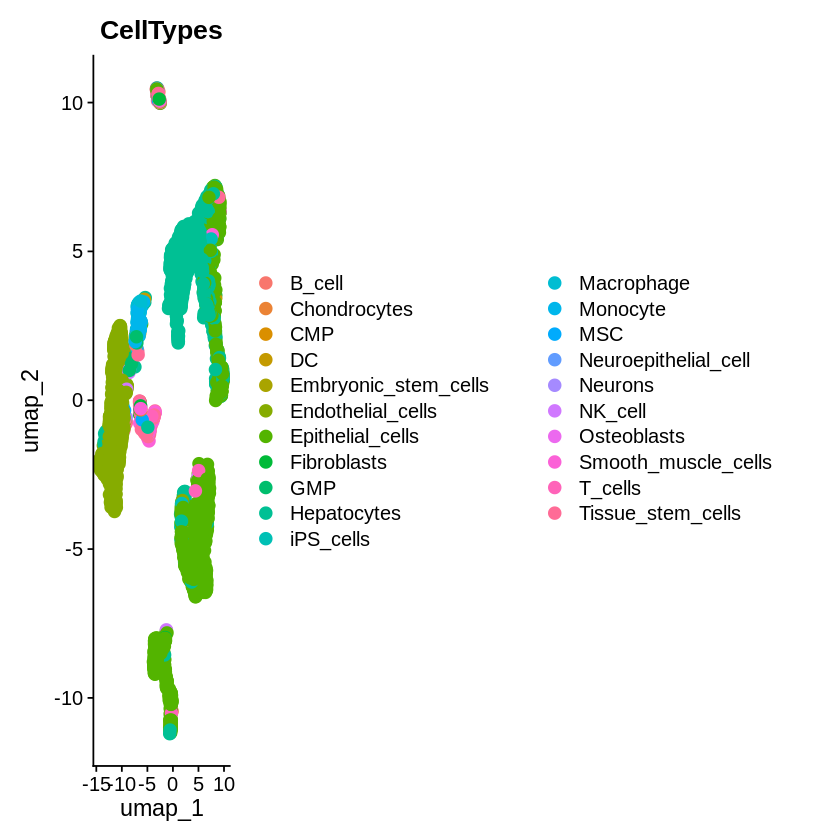

In [ ]:
DimPlot(data_scaled_joined, reduction = "umap", pt.size = 3, group.by = "CellTypes")

**Reading the result.** SingleR can only choose from labels in the Human Primary Cell Atlas, which has no real kidney cell types, so the labels must be read with care:

* **Epithelial_cells (1,133)** is the closest match for kidney tubular cells, and the label used for the DKD vs Normal comparison in section 14.
* **Hepatocytes (834)** are certainly not liver cells in a kidney sample. These are most likely proximal-tubule cells, which share many metabolic genes with hepatocytes.
* **Endothelial_cells (568)** and the small immune groups (Macrophage, Monocyte, T_cells, NK_cell, ...) are plausible.
* Labels such as Chondrocytes, Embryonic_stem_cells or Neurons, with only a few cells each, are most probably mis-assignments.

This is exactly the situation where a second, tissue-specific method is needed.

### 12.2 Marker-based (manual) annotation

Here you decide the cell type of each cluster yourself, from marker genes. Sources of markers: the literature, CellMarker 2.0, PanglaoDB, and your own knowledge of the tissue.

**Step 1: browse the CellMarker database.** It lists, for every tissue and cell type, the marker genes reported in the literature. Use it to look up which cell types a gene marks (for example *PODXL* marks podocytes) and to see all kidney entries.

In [ ]:
cm_url  <- "http://www.bio-bigdata.center/CellMarker_download_files/file/Cell_marker_Human.xlsx"
cm_file <- file.path(data_dir, "Cell_marker_Human.xlsx")
if (!file.exists(cm_file)) download.file(cm_url, cm_file, mode = "wb")

library(readxl)
annot_cell_marker02 <- as.data.frame(read_excel(cm_file))

# all kidney entries
head(annot_cell_marker02[annot_cell_marker02$tissue_type == "Kidney", ])

,species,tissue_class,tissue_type,uberonongology_id,cancer_type,cell_type,cell_name,cellontology_id,marker,Symbol,GeneID,Genetype,Genename,UNIPROTID,technology_seq,marker_source,PMID,Title,journal,year
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>
31626,Human,Kidney,Kidney,UBERON_0002113,Normal,Normal cell,Epithelial cell,CL_0000066,MCAB51,NA,NA,NA,NA,NA,NA,Experiment,2992716,Presence of a novel epithelial antigen on rat cerebellar cell lines as detected by a monoclonal antibody.,Brain research,1985
31627,Human,Kidney,Kidney,UBERON_0002113,Normal,Normal cell,Epithelial cell,CL_0000066,ZO-1,TJP1,7082,protein_coding,tight junction protein 1,A9CQZ8,NA,Experiment,9124399,Met -/- kidneys express epithelial cells that chemotax and form tubules in response to EGF receptor ligands.,The American journal of physiology,1997
31628,Human,Kidney,Kidney,UBERON_0002113,Normal,Normal cell,Epithelial cell,CL_0000066,E-cadherin,NA,NA,NA,NA,NA,NA,Experiment,9124399,Met -/- kidneys express epithelial cells that chemotax and form tubules in response to EGF receptor ligands.,The American journal of physiology,1997
31629,Human,Kidney,Kidney,UBERON_0002113,Normal,Normal cell,Epithelial cell,CL_0000066,Cytokeratin,NA,NA,NA,NA,NA,NA,Experiment,9124399,Met -/- kidneys express epithelial cells that chemotax and form tubules in response to EGF receptor ligands.,The American journal of physiology,1997
31630,Human,Kidney,Kidney,UBERON_0002113,Normal,Normal cell,Proximal tubular cell,NA,Intestinal Alkaline Phosphatase,NA,NA,NA,NA,NA,NA,Experiment,9263997,"Immunodissection of the human proximal nephron: flow sorting of S1S2S3, S1S2 and S3 proximal tubular cells.",Kidney international,1997
31633,Human,Kidney,Kidney,UBERON_0002113,Normal,Normal cell,Mesangial cell,CL_0000650,CD34,CD34,2210,protein_coding,Fc fragment of IgG receptor Ib,NA,NA,Experiment,10451496,CD34 expression as a novel marker of transformed mesangial cells in biopsied glomerular diseases.,The Journal of pathology,1999


In [ ]:
# in which tissues / cell types is a given gene a marker?
head(annot_cell_marker02[annot_cell_marker02$marker == "PODXL", ])

,X,species,tissue_class,tissue_type,uberonongology_id,cancer_type,cell_type,cell_name,cellontology_id,marker,⋯,GeneID,Genetype,Genename,UNIPROTID,technology_seq,marker_source,PMID,Title,journal,year
,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>
19511,19511,Human,Embryo,Embryo,UBERON_0000922,Normal,Normal cell,Epithelial progenitor cell,CL_0000158,PODXL,⋯,5420,protein_coding,podocalyxin like,O00592,10x Chromium,Experiment,30827876,Single-Cell RNA Sequencing of Human Embryonic Stem Cell Differentiation Delineates Adverse Effects of Nicotine on Embryonic Development,Stem cell reports,2019
19910,19910,Human,Embryo,Embryo,UBERON_0000922,Neuroblastoma,Cancer cell,Stem cell,CL_0000034,PODXL,⋯,5420,protein_coding,podocalyxin like,O00592,None,Experiment,34655293,Human embryonic stem cell-derived neural crest model unveils CD55 as a cancer stem cell regulator for therapeutic targeting in MYCN-amplified neuroblastoma,Neuro-oncology,2021
28239,28239,Human,Gonad,Fetal gonad,NA,Normal,Normal cell,Gonadal mitotic phase fetal germ cell,CL_0000115,PODXL,⋯,5420,protein_coding,podocalyxin like,O00592,NA,Single-cell sequencing,28457750,Single-Cell RNA-Seq Analysis Maps Development of Human Germline Cells and Gonadal Niche Interactions.,Cell stem cell,2017
28457,28457,Human,Gonad,Fetal gonad,NA,Normal,Normal cell,Mitotic fetal germ cell,CL_0000586,PODXL,⋯,5420,protein_coding,podocalyxin like,O00592,NA,Single-cell sequencing,28457750,Single-Cell RNA-Seq Analysis Maps Development of Human Germline Cells and Gonadal Niche Interactions.,Cell stem cell,2017
28689,28689,Human,Heart,Embryonic heart,UBERON_0006283,Normal,Normal cell,Stem cell,CL_0000034,PODXL,⋯,5420,protein_coding,podocalyxin like,O00592,None,Experiment,31465963,Landscape of Enhancer-Enhancer Cooperative Regulation during Human Cardiac Commitment,Molecular therapy. Nucleic acids,2019
30004,30004,Human,Intestine,Large intestine,UBERON_0000059,Normal,Normal cell,MKI67+ progenitor cell,NA,PODXL,⋯,5420,protein_coding,podocalyxin like,O00592,NA,Single-cell sequencing,29802404,Tracing the temporal-spatial transcriptome landscapes of the human fetal digestive tract using single-cell RNA-sequencing.,Nature cell biology,2018


**Step 2: build a marker panel for the expected kidney (and immune) cell types** and look at it per cluster with a dot plot. Check that no gene is listed under two cell types (it would be uninformative); the duplicate check below should return an empty result.

| Group | Meaning |
| --- | --- |
| Podocyte | glomerular filtration barrier |
| Proximal_Tubule | PT |
| DCT_LOH / DCT | thick ascending limb of Henle / distal convoluted tubule |
| CD_PC / CD_IC | collecting duct principal / intercalated cells |
| Endothelial, Fb | endothelium, fibroblasts |
| Mono, Neutrophils, Mast, Macrophage, Myeloid | myeloid lineage |
| T_cell, B_cell, T_NK | lymphoid lineage |

In [ ]:
marker_list <- list(
    Podocyte = c(
        "NPHS1", "WT1", "PODXL", "SYNPO"
    ),

    Proximal_Tubule = c(
        "LRP2", "CUBN", "SLC27A2", "SLC34A1", "ALDOB"
    ),

    Endothelial = c(
        "PECAM1", "EMCN", "VWF", "KDR"
    ),

    Mono = "CLEC12A",

    Neutrophils = c(
        "S100A9", "S100A8"
    ),

    Mast = c(
        "TPSB2", "TPSAB1"
    ),

    Macrophage = c(
        "C1QB", "C1QA"
    ),

    DCT_LOH = "SLC12A1",

    DCT = c(
        "WNK1", "CALB1"
    ),

    CD_PC = c(
        "AQP2", "AQP3"
    ),

    CD_IC = c(
        "ATP6V0D2", "ATP6V1G3"
    ),

    Fb = c(
        "COL1A2", "PDGFRB"
    ),

    T_cell = c(
        "CD3D", "CD3G", "CD3E", "TRBC1", "TRBC2"
    ),

    B_cell = c(
        "MS4A1", "CD79A", "CD79B", "CD37"
    ),

    T_NK = c(
        "NKG7", "KLRB1", "S100A4"
    ),

    Myeloid = c(
        "LYZ", "TYROBP", "FCER1G"
    )
)

# a gene should appear in only one group
all_markers <- unlist(marker_list)
all_markers[duplicated(all_markers)]

Plot the panel on the uncorrected `RNA` assay (all genes available, true normalized expression). This also fixes the problem of the earlier dot plot, where genes outside the 2,000 integrated genes were missing.

In [ ]:
DefaultAssay(data_scaled_joined) <- "RNA"
DefaultAssay(data_scaled_joined)

[1] "RNA"

In [ ]:
options(repr.plot.width = 18, repr.plot.height = 8)
p_dot <- DotPlot(data_scaled_joined, features = marker_list, group.by = "seurat_clusters") + RotatedAxis()
p_dot
options(repr.plot.width = 7, repr.plot.height = 7)

ggsave(file.path(proj_dir, "dotplot_marker_based.png"), p_dot, width = 18, height = 8, dpi = 150)

**Step 3: assign labels to clusters.** Write the cluster -> label decisions into a metadata column. `"NA"` marks clusters not yet annotated; the review step (section 13) treats these as *Unassigned*.

> Note: clusters 0, 13 and 14 refer to the resolution-0.8 clustering (`seurat_clusters`), while the `T_CELL` label for cluster 9 was taken from the resolution-1 clustering (`integrated_snn_res.1`); the clustree suggests that cluster 9 is the same group of cells at both resolutions. Cluster numbers differ between resolutions, so use **one** resolution for all manual labels when you extend this list.

In [ ]:
data_scaled_joined@meta.data$cell_annot_cellMArker02 <- "NA"   # "NA" = not annotated yet

data_scaled_joined@meta.data$cell_annot_cellMArker02[which(data_scaled_joined@meta.data$seurat_clusters == 0)]  <- "Proximal_tube"
data_scaled_joined@meta.data$cell_annot_cellMArker02[which(data_scaled_joined@meta.data$seurat_clusters == 13)] <- "myeloid_Bcell like"
data_scaled_joined@meta.data$cell_annot_cellMArker02[which(data_scaled_joined@meta.data$seurat_clusters == 14)] <- "CD_PC"
data_scaled_joined@meta.data$cell_annot_cellMArker02[which(data_scaled_joined@meta.data$integrated_snn_res.1 == 9)] <- "T_CELL"

table(data_scaled_joined@meta.data$cell_annot_cellMArker02)

### 12.3 Reference mapping (label transfer) with a kidney atlas

Instead of correlating with a generic atlas, we map our cells onto an **annotated kidney single-cell reference** (the Stewart et al. kidney dataset provided as a demo by Azimuth). Seurat finds **anchors** between query and reference cells in the reference's PCA space and transfers the reference labels to the query cells. Every cell also gets a **prediction score** (0 to 1), a built-in confidence measure.

**Step 1: download and inspect the reference.**

In [ ]:
ref_file <- file.path(data_dir, "kidney_demo_stewart.rds")
if (!file.exists(ref_file)) download.file("https://seurat.nygenome.org/azimuth/demo_datasets/kidney_demo_stewart.rds", ref_file, mode = "wb")
kidney_ref <- readRDS(ref_file)

Assays(kidney_ref)
Reductions(kidney_ref)   # NULL: the reference ships without a PCA, we compute one below
colnames(kidney_ref@meta.data)

[1] "RNA"

NULL

[1] "orig.ident"     "nCount_RNA"     "nFeature_RNA"   "Project"       
[5] "Experiment"     "celltype"       "compartment"    "broad_celltype"

In [ ]:
table(kidney_ref$celltype)   # the labels that can be transferred


     Ascending vasa recta endothelium                                B cell 
                                  196                                   759 
                           CD4 T cell                            CD8 T cell 
                                  948                                   556 
                    Connecting tubule     Descending vasa recta endothelium 
                                  149                                   165 
           Distinct proximal tubule 1            Distinct proximal tubule 2 
                                   60                                   121 
           Epithelial progenitor cell                            Fibroblast 
                                  213                                    23 
               Glomerular endothelium          Indistinct intercalated cell 
                                  604                                   429 
                            Mast cell      MNP-a/classical monocyte derived

**Step 2: prepare the reference.** Label transfer by PCA projection needs a PCA in the reference, so normalize, find variable genes, scale and run PCA on it first. (Without this, `FindTransferAnchors` stops with *reference.reduction (pca) is not present in the provided reference object*.)

In [ ]:
DefaultAssay(kidney_ref) <- "RNA"

kidney_ref <- NormalizeData(kidney_ref, normalization.method = "LogNormalize")
kidney_ref <- FindVariableFeatures(kidney_ref)
kidney_ref <- ScaleData(kidney_ref)
kidney_ref <- RunPCA(kidney_ref, npcs = 50)

Centering and scaling data matrix

PC_ 1 
Positive:  KRT19, TACSTD2, CLDN4, FXYD3, ELF3, GDF15, MUC1, WFDC2, SLPI, PSCA 
	   KRT7, S100P, CLDN7, SMIM22, SNCG, SPINK1, GPRC5A, CAPS, LCN2, KRT18 
	   AGR2, CXADR, IGFBP3, SPINT2, CD9, MMP7, UPK2, KRT17, ATF3, MDK 
Negative:  LTB, MS4A1, CD79A, GPR183, TRGC2, CCL4, AL928768.3, IFNG, IRF8, RGS1 
	   RP5-887A10.1, GZMB, CD27, PLEK, FCGR3A, SPON2, IGHG1, IGHA1, GSTA2, IGHA2 
	   CCR7, GNLY, IGHG3, XCL2, IGHG2, XCL1, IGLC2, TRDC, CCL4L2, UGT2B7 
PC_ 2 
Positive:  CD24, PPDPF, CKB, ATP6V1B1, ATP6V1G3, KRT8, ATP6V0D2, PTGER3, ATP1B1, TMEM213 
	   KRT18, MAL, EPCAM, SPP1, EMX2, CXCL14, ATP6V1C2, FAM24B, ATP6V0A4, CLCNKA 
	   GRB14, SMIM5, VAMP8, SMIM6, SCIN, CLCNKB, DEFB1, UGT2B7, GMPR, CA12 
Negative:  IFI27, TIMP3, EMCN, TM4SF1, SLC9A3R2, MGP, HLA-DRB1, SDPR, PLAT, PODXL 
	   IGFBP5, ADGRL4, PTRF, HLA-DRA, CRHBP, GSN, PLPP3, HLA-DPA1, CLEC14A, ADGRF5 
	   HLA-DPB1, ID1, UACA, CRIP2, APOLD1, CD93, FCN3, KLF4, TIMP1, HLA-DQA1 
PC_ 3 
Positive:  T

**Step 3: prepare the query.** Work on a copy of our object, set its default assay to the uncorrected `RNA` assay (the reference is raw-count based, so the batch-corrected `integrated` assay must not be used) and log-normalize it.

In [ ]:
kidney_query <- data_scaled_joined
DefaultAssay(kidney_query) <- "RNA"

kidney_query <- NormalizeData(kidney_query, assay = "RNA", normalization.method = "LogNormalize")

Assays(kidney_query)
DefaultAssay(kidney_query)

Normalizing layer: counts

[1] "RNA"        "integrated"

[1] "RNA"

**Step 4: genes shared by reference and query.** The two objects use different gene-annotation versions (for example `RP11-34P13.3` in the reference vs `AL627309.1` in the query), so only part of the genes overlap. We pass the shared genes to the anchor search explicitly. (Without `features`, Seurat reported *No features to use in finding transfer anchors*.)

In [ ]:
length(rownames(kidney_ref))
length(rownames(kidney_query))

head(rownames(kidney_ref))
head(rownames(kidney_query))

common_genes <- intersect(rownames(kidney_ref), rownames(kidney_query))
length(common_genes)

[1] 33694

[1] 21037

[1] "RP11-34P13.3"  "FAM138A"       "OR4F5"         "RP11-34P13.7" 
[5] "RP11-34P13.8"  "RP11-34P13.14"

[1] "AL627309.1" "AL627309.5" "LINC01409"  "LINC01128"  "LINC00115" 
[6] "FAM41C"

[1] 16337

**Step 5: find anchors and transfer the labels.**

In [ ]:
kidney_anchors <- FindTransferAnchors(
    reference = kidney_ref,
    query = kidney_query,
    reference.assay = "RNA",
    query.assay = "RNA",
    normalization.method = "LogNormalize",
    reference.reduction = "pca",
    reduction = "pcaproject",
    features = common_genes,
    dims = 1:30
)

Projecting cell embeddings

Finding neighborhoods

Finding anchors

	Found 1774 anchors

In [ ]:
kidney_predictions <- TransferData(
    anchorset = kidney_anchors,
    refdata = kidney_ref$celltype,
    dims = 1:30
)

kidney_query <- AddMetaData(kidney_query, metadata = kidney_predictions)

Finding integration vectors

Finding integration vector weights

Predicting cell labels

`predicted.id` is the transferred label and `prediction.score.max` its confidence; there is also one `prediction.score.<label>` column per reference cell type.

**Step 6: look at the result.** The t-SNE coloured by predicted label (also saved to a PNG), and a table of predicted labels per cluster at resolution 1 (rows = clusters, columns = labels; wide, so it wraps over several blocks).

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)
p_pred <- DimPlot(kidney_query, reduction = "tsne", group.by = "predicted.id", label = TRUE, repel = TRUE)
p_pred
options(repr.plot.width = 7, repr.plot.height = 7)

ggsave(file.path(proj_dir, "pred_kidney_ref_tsne.png"), p_pred, width = 16, height = 14, dpi = 120)

In [ ]:
table(kidney_query$`integrated_snn_res.1`, kidney_query$predicted.id)

    
     Ascending vasa recta endothelium Connecting tubule
  0                                 0                 0
  1                                 0                 1
  2                                77                 1
  3                                 0                 1
  4                                 0                 2
  5                                 0                 6
  6                                 0                 5
  7                                 0                 0
  8                               136                 0
  9                                15                 0
  10                                0                 0
  11                                0                54
  12                                0                 0
  13                                0                 0
  14                                7                 1
  15                                0                40
  16                               74      

Most clusters are dominated by a single reference label (for example cluster 0 onto *Distinct proximal tubule 1*, cluster 4 onto *Proximal tubule*, cluster 7 onto *Myofibroblast*, cluster 8 onto *Ascending vasa recta endothelium*). A few are split between related types (cluster 2 between endothelial and stromal labels; clusters 11 and 15 between connecting-tubule, intercalated and principal-cell labels). The review step in section 13 quantifies this per cluster.

## 13. Final annotation review: choose which labels to keep

At this point every cell carries up to **three independent labels**:

| Metadata column | Method | Resolution of the label |
| --- | --- | --- |
| `CellTypes` | SingleR + Human Primary Cell Atlas (12.1) | per cell |
| `predicted.id` (+ `prediction.score.max`) | kidney reference mapping (12.3) | per cell, with a confidence score |
| `cell_annot_cellMArker02` | marker-based manual labels (12.2) | per cluster, partly annotated |

They will not agree everywhere, so this section is a **review step**: compare them, decide which one (or which combination) to trust, and store the decision as a single column, `final_celltype`, which is then used for the UMAP and for the downstream analysis.

```text
                 Your scRNA-seq data
                         |
                         v
                 Unsupervised analysis
                         |
                         v
                      Clusters
                         |
            +------------+------------+
            v                         v
      Manual markers            Automated annotation
            |                         |
            +------------+------------+
                         v
                    Compare them
                         |
             +-----------+-----------+
             v                       v
          Agreement              Disagreement
             |                       |
             v                       v
        High confidence        Investigate deeply
             |                       |
             +-----------+-----------+
                         v
                  Final annotation
```

**How to decide**

* **Agreement between independent methods means high confidence.** A cluster that SingleR, the kidney reference and your markers all call (some form of) proximal tubule is safe.
* **Disagreement means investigate**: look at the marker dot plot for that cluster, at the reference prediction score, and ask whether the label exists in the method's vocabulary at all.
* **A method cannot name what it does not contain.** The Human Primary Cell Atlas has no kidney tubule, so it returns the nearest thing (hepatocyte). A kidney reference does know these cell types, which is why it is usually the better per-cell source here.
* **Use the confidence score.** Reference labels with a low `prediction.score.max` are unreliable; they become `Unassigned` instead of being forced into a wrong class.
* **Individual clusters can still be corrected by hand** (`cluster_overrides`), exactly like the manual annotation in 12.2.

**What the code below does**

1. **Collect** the three labelings into tidy columns `anno_singler`, `anno_reference` (low-confidence cells set to `Unassigned`) and `anno_manual` (not-annotated set to `Unassigned`).
2. **Compare** them side by side on the UMAP and look at the reference confidence.
3. **Summarize per cluster**: for each cluster the dominant label (and the share of cells that carry it) from each method, in one table.
4. **Decide**: pick the source in `final_source`, optionally correct single clusters with `cluster_overrides`.
5. **Build and validate** `final_celltype`: show it on the UMAP, cross-tabulate it with the condition, check it against the marker panel, and save the result.

### 13.1 Collect the labels in one place

In [ ]:
# The reference-mapping results live in `kidney_query` (a copy of the object).
# Add them to the main object once.
if (!"predicted.id" %in% colnames(data_scaled_joined@meta.data)) {
  data_scaled_joined <- AddMetaData(
    data_scaled_joined,
    metadata = kidney_query@meta.data[, c("predicted.id", "prediction.score.max")]
  )
}

# ------------------------------ settings ------------------------------
cluster_col  <- "seurat_clusters"  # clustering used for the per-cluster review (resolution 0.8)
score_cutoff <- 0.5                # reference labels with a lower confidence score become "Unassigned"
# ----------------------------------------------------------------------

meta <- data_scaled_joined@meta.data
tidy <- data.frame(
  anno_singler   = as.character(meta$CellTypes),
  anno_reference = ifelse(meta$prediction.score.max >= score_cutoff,
                          as.character(meta$predicted.id), "Unassigned"),
  anno_manual    = ifelse(is.na(meta$cell_annot_cellMArker02) | meta$cell_annot_cellMArker02 == "NA",
                          "Unassigned", as.character(meta$cell_annot_cellMArker02)),
  row.names = rownames(meta),
  stringsAsFactors = FALSE
)
data_scaled_joined <- AddMetaData(data_scaled_joined, metadata = tidy)

# how many cells carry each label, per method
lapply(tidy, function(x) sort(table(x), decreasing = TRUE))

### 13.2 Compare the methods on the UMAP

Same UMAP, one panel per method. Look for regions where the panels tell different stories, and for large `Unassigned` areas.

In [ ]:
titles <- c(anno_singler   = "SingleR (Human Primary Cell Atlas)",
            anno_reference = "Kidney reference mapping",
            anno_manual    = "Manual (markers / CellMarker)")

options(repr.plot.width = 20, repr.plot.height = 7)
plots <- lapply(names(titles), function(col) {
  DimPlot(data_scaled_joined, reduction = "umap", group.by = col,
          label = TRUE, repel = TRUE, pt.size = 1) +
    ggtitle(titles[[col]]) + NoLegend()
})
wrap_plots(plots, ncol = 3)
options(repr.plot.width = 7, repr.plot.height = 7)

How confident is the reference mapping? Cells to the left of the dashed line are the ones that become `Unassigned`; a UMAP region with low scores usually means a cell type or state that the reference does not contain (or poor-quality cells).

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 5)
p_score <- FeaturePlot(data_scaled_joined, features = "prediction.score.max", reduction = "umap") +
  ggtitle("Reference-mapping confidence")
p_score
options(repr.plot.width = 7, repr.plot.height = 7)

hist(data_scaled_joined$prediction.score.max, breaks = 50,
     main = "Reference-mapping prediction score", xlab = "prediction.score.max")
abline(v = score_cutoff, col = "red", lty = 2)

### 13.3 Per-cluster comparison table

One row per cluster with the **dominant label of each method and the percentage of the cluster's cells that carry it**. Also shown: the mean reference confidence and the share of cells above the cut-off. Reading it:

* the same cell type in the SingleR and Reference columns (even with different names, e.g. *Epithelial_cells* vs *Proximal tubule*) and high percentages: high confidence;
* a low percentage means the cluster is a mixture for that method;
* a low `ref_score` or low `pct_above_cutoff` means the reference does not recognize the cluster well;
* compare with the marker dot plot from 12.2 to settle disagreements.

**A disagreement to resolve in this dataset.** Cluster 9 was labelled `T_CELL` manually (it stands out for CD3D, CD3E, NKG7 and GNLY in the dot plots), but the reference mapping assigns most of its cells to vasa-recta endothelium (section 12.3), and SingleR finds only 5 T cells in the entire dataset. The three methods cannot all be right. Check CD3D/CD3E against endothelial markers such as PECAM1 and EMCN for this cluster on the `RNA` assay before keeping the label (the first dot plot was drawn on the 2,000-gene `integrated` assay). A similar question applies to clusters that the reference calls *Epithelial progenitor cell*: a broad label like that may be capturing a cell state (for example injured or stressed tubular cells) rather than a distinct cell type.

In [ ]:
top_label <- function(x) {
  tab <- sort(table(x), decreasing = TRUE)
  sprintf("%s (%.0f%%)", names(tab)[1], 100 * tab[[1]] / length(x))
}

meta <- data_scaled_joined@meta.data
by_cluster <- split(meta, meta[[cluster_col]])

review <- do.call(rbind, lapply(names(by_cluster), function(cl) {
  d <- by_cluster[[cl]]
  data.frame(
    cluster          = cl,
    n_cells          = nrow(d),
    SingleR          = top_label(d$anno_singler),
    Reference        = top_label(d$anno_reference),
    ref_score        = round(mean(d$prediction.score.max), 2),
    pct_above_cutoff = round(100 * mean(d$anno_reference != "Unassigned")),
    Manual           = top_label(d$anno_manual),
    stringsAsFactors = FALSE
  )
}))
review

### 13.4 Decide and build the final annotation

Two choices, both in the cell below:

* **`final_source`**: which method provides the base label for every cell.
  * `"singler"`: SingleR labels. This is the **starting setting**, because the DKD vs Normal results saved in section 14 were computed with the SingleR group `Epithelial_cells`, so code and saved results stay consistent.
  * `"reference"`: kidney reference labels, low-confidence cells set to `Unassigned`. For kidney this is usually the more reliable choice and gives fine cell types (see the table above). Switch to it once you are satisfied with the review.
  * `"manual"`: your marker-based cluster labels (only the clusters you have labelled).
* **`cluster_overrides`**: optional corrections for single clusters, applied *on top of* `final_source`. Every cell in the named cluster gets that label.

> If you change `final_source`, also update `deg_celltypes` in section 14 so that it names a label that exists in the new `final_celltype` (the code stops with a message that lists the available labels if it does not).

In [ ]:
# ============================ YOUR DECISION ============================
final_source <- "singler"      # "singler" | "reference" | "manual"

# Optional per-cluster corrections (cluster ids come from `cluster_col`), e.g.
# cluster_overrides <- c("13" = "Myeloid", "9" = "T cell")
cluster_overrides <- character(0)
# =======================================================================

anno_columns <- c(singler = "anno_singler", reference = "anno_reference", manual = "anno_manual")
stopifnot(final_source %in% names(anno_columns))

final <- as.character(data_scaled_joined@meta.data[[anno_columns[[final_source]]]])

if (length(cluster_overrides) > 0) {
  cl  <- as.character(data_scaled_joined@meta.data[[cluster_col]])
  hit <- cl %in% names(cluster_overrides)
  final[hit] <- unname(cluster_overrides[cl[hit]])
}

data_scaled_joined$final_celltype <- final
Idents(data_scaled_joined) <- "final_celltype"

sort(table(data_scaled_joined$final_celltype), decreasing = TRUE)

### 13.5 Display and validate the final annotation

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 7)
DimPlot(data_scaled_joined, reduction = "umap", group.by = "final_celltype",
        label = TRUE, repel = TRUE, pt.size = 1.5)
options(repr.plot.width = 7, repr.plot.height = 7)

Cells per final label and condition. This also shows whether a comparison between Normal and DKD within a given label is feasible (you want a reasonable number of cells in both columns):

In [ ]:
table(data_scaled_joined$final_celltype, data_scaled_joined$sample_type)

Last biological sanity check: the canonical marker panel grouped by the **final** labels. Each label should light up its own markers (podocyte markers in podocytes, `SLC12A1` in the thick ascending limb, `LYZ`/`TYROBP` in myeloid cells, and so on). If a label does not, go back to 13.3 and fix it with `cluster_overrides`.

In [ ]:
options(repr.plot.width = 18, repr.plot.height = 8)
DotPlot(data_scaled_joined, features = marker_list, group.by = "final_celltype") + RotatedAxis()
options(repr.plot.width = 7, repr.plot.height = 7)

### 13.6 Save the annotation

Keep a flat table with every method's label for every cell (so the decision can be audited later) and save the annotated object as a checkpoint.

Set `prune_metadata <- TRUE` **only at the very end** if you want to remove the intermediate label columns from the object and keep just `final_celltype`; the review cells above need those columns, so do not prune before you are done.

In [ ]:
annotation_table <- data.frame(
  cell = rownames(data_scaled_joined@meta.data),
  data_scaled_joined@meta.data[, c("sample_type", cluster_col, "anno_singler", "anno_reference",
                                   "prediction.score.max", "anno_manual", "final_celltype")],
  check.names = FALSE
)
write.csv(annotation_table, file.path(proj_dir, "annotation_table.csv"), row.names = FALSE)

# optional: drop the intermediate label columns from the object
prune_metadata <- FALSE
if (prune_metadata) {
  for (col in c("CellTypes", "cell_annot_cellMArker02", "predicted.id",
                "anno_singler", "anno_reference", "anno_manual")) {
    data_scaled_joined[[col]] <- NULL
  }
}

SaveSeuratRds(data_scaled_joined, file = file.path(proj_dir, "scRNA_annotated.Rds"))

## 14. Differential expression: DKD vs Normal

With cell types defined, we can ask the disease question *within a cell type*: which genes differ between DKD and normal cells of the same type? Comparing within a type avoids mistaking a change in cell-type composition for a change in gene expression.

The cells to compare come from the **final annotation** (section 13): set `deg_celltypes` to the label or labels of interest. The saved results below were computed for the SingleR group `Epithelial_cells` (629 Normal and 504 DKD cells).

We use **limma** on the log-normalized expression of the `RNA` assay (not the batch-corrected `integrated` assay): a linear model per gene with a *DKD - Normal* contrast, and empirical-Bayes moderation of the variances.

### 14.1 Free memory and select the cells

The raw objects and intermediate tables are no longer needed; removing them frees RAM for the dense expression matrix below.

In [ ]:
to_remove <- c("dkd_sub", "DKD1", "DKD1_data", "DKD2", "DKD2_data", "DKD3", "DKD3_data",
               "DKDs", "DKDs_joined", "g2m_genes", "i", "intfeature", "labs", "marker_panel",
               "markers", "NM1", "NM1_data", "NM2", "NM2_data", "NM3", "NM3_data", "norm_sub",
               "normals", "normals_joined", "p1", "p2", "p3", "plot1", "plot2", "ref", "s_genes",
               "scaled_matrix", "top_markers", "top10_DKDs", "top10_norms", "vec",
               "count_matrix_NM1", "count_matrix_NM2", "count_matrix_raw_2", "count_matrix_norm_2",
               "count_matrix_normal_joined", "count_matrix_int")
rm(list = intersect(to_remove, ls()))
invisible(gc())

In [ ]:
# label(s) in `final_celltype` to compare DKD vs Normal in
deg_celltypes <- "Epithelial_cells"

cells_use <- which(data_scaled_joined$final_celltype %in% deg_celltypes)
if (length(cells_use) == 0) {
  stop("No cells carry the label(s): ", paste(deg_celltypes, collapse = ", "),
       "\nAvailable labels: ", paste(sort(unique(data_scaled_joined$final_celltype)), collapse = "; "))
}
table(data_scaled_joined$final_celltype[cells_use], data_scaled_joined$sample_type[cells_use])

Take the log-normalized expression of just these cells (sparse to dense only for the selected cells) and split them by condition. Normal cells go first, then DKD cells.

In [ ]:
expr <- GetAssayData(data_scaled_joined, assay = "RNA", layer = "data")[, cells_use]
deg_cells <- as.data.frame(as.matrix(expr))
head(deg_cells)

is_normal    <- data_scaled_joined$sample_type[cells_use] == "Normal"
Normal_cells <- deg_cells[, is_normal, drop = FALSE]
DKD_cells    <- deg_cells[, !is_normal, drop = FALSE]

,Normal-1_AAAGTCCCAATTCACG-1,Normal-1_AACAACCTCATTCCTA-1,Normal-1_AACCACAAGGGATGTC-1,Normal-1_AACGTCACAAACTAGA-1,Normal-1_AAGACTCCAGCTGTTA-1,Normal-1_ACAACCACAATCCAGT-1,Normal-1_ACACTGAAGTTGCATC-1,Normal-1_ACCAAACCAATACGCT-1,Normal-1_ACGGGTCAGTGCAGGT-1,Normal-1_ACGTCCTAGGTAAGGA-1,⋯,DKD-03_TGTCCACGTGTCATGT-1,DKD-03_TGTTCTAGTGAGGCAT-1,DKD-03_TTACGTTGTTCTCCTG-1,DKD-03_TTCATGTCACCAGGTC-1,DKD-03_TTCCAATAGCGAAACC-1,DKD-03_TTCTGTAGTAATGCGG-1,DKD-03_TTCTTCCTCGAACCAT-1,DKD-03_TTGAGTGAGAATAACC-1,DKD-03_TTGGATGAGGATGGCT-1,DKD-03_TTGTTTGAGGCGAACT-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AL627309.1,0,0,0,0,0,0,0,0.2169699,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0
AL627309.5,0,0,0,0,0,0,0,0.0000000,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0
LINC01409,0,0,0,0,0,0,0,0.0000000,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0
LINC01128,0,0,0,0,0,0,0,0.0000000,0.189163,0,⋯,0.233763,0.1859041,0,0,0,0,0,0,0,0
LINC00115,0,0,0,0,0,0,0,0.0000000,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0
FAM41C,0,0,0,0,0,0,0,0.0000000,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0


In [ ]:
# optional exports of the per-condition expression tables
write.table(Normal_cells, file.path(proj_dir, "DEG_input_Normal_cells.txt"), sep = "\t", quote = FALSE)
write.table(DKD_cells,    file.path(proj_dir, "DEG_input_DKD_cells.txt"),    sep = "\t", quote = FALSE)

In [ ]:
deg_count <- cbind(Normal_cells, DKD_cells)
dim(deg_count)    # genes x cells
head(deg_count)

length(grep("Normal", colnames(deg_count)))
length(grep("DKD", colnames(deg_count)))

[1] 21037  1133

,Normal-1_AAAGTCCCAATTCACG-1,Normal-1_AACAACCTCATTCCTA-1,Normal-1_AACCACAAGGGATGTC-1,Normal-1_AACGTCACAAACTAGA-1,Normal-1_AAGACTCCAGCTGTTA-1,Normal-1_ACAACCACAATCCAGT-1,Normal-1_ACACTGAAGTTGCATC-1,Normal-1_ACCAAACCAATACGCT-1,Normal-1_ACGGGTCAGTGCAGGT-1,Normal-1_ACGTCCTAGGTAAGGA-1,⋯,DKD-03_TGTCCACGTGTCATGT-1,DKD-03_TGTTCTAGTGAGGCAT-1,DKD-03_TTACGTTGTTCTCCTG-1,DKD-03_TTCATGTCACCAGGTC-1,DKD-03_TTCCAATAGCGAAACC-1,DKD-03_TTCTGTAGTAATGCGG-1,DKD-03_TTCTTCCTCGAACCAT-1,DKD-03_TTGAGTGAGAATAACC-1,DKD-03_TTGGATGAGGATGGCT-1,DKD-03_TTGTTTGAGGCGAACT-1
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AL627309.1,0,0,0,0,0,0,0,0.2169699,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0
AL627309.5,0,0,0,0,0,0,0,0.0000000,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0
LINC01409,0,0,0,0,0,0,0,0.0000000,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0
LINC01128,0,0,0,0,0,0,0,0.0000000,0.189163,0,⋯,0.233763,0.1859041,0,0,0,0,0,0,0,0
LINC00115,0,0,0,0,0,0,0,0.0000000,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0
FAM41C,0,0,0,0,0,0,0,0.0000000,0.000000,0,⋯,0.000000,0.0000000,0,0,0,0,0,0,0,0


[1] 629

[1] 504

### 14.2 Sample table and model

The sample table tells limma which column belongs to which group. The design matrix has one column per group (`~ 0 + group`), and the contrast `DKD - Normal` asks which genes are higher (positive log fold-change) or lower (negative) in DKD.

In [ ]:
metadata <- data.frame(
  SampleName = colnames(deg_count),
  SampleType = c(rep("Normal", ncol(Normal_cells)), rep("DKD", ncol(DKD_cells)))
)
tail(metadata)

,SampleName,SampleType
,<chr>,<chr>
1128,DKD-03_TTCCAATAGCGAAACC-1,DKD
1129,DKD-03_TTCTGTAGTAATGCGG-1,DKD
1130,DKD-03_TTCTTCCTCGAACCAT-1,DKD
1131,DKD-03_TTGAGTGAGAATAACC-1,DKD
1132,DKD-03_TTGGATGAGGATGGCT-1,DKD
1133,DKD-03_TTGTTTGAGGCGAACT-1,DKD


> **Check this step.** The two lines below convert the expression values to integers. `as.integer()` *truncates* (2.7 becomes 2), which throws away most of the information in log-normalized values (typically between 0 and about 5). limma is designed for continuous log-expression, so the model can be fitted directly on `deg_count`, optionally with `eBayes(..., trend = TRUE)`. The saved results below were produced *with* the truncation, so the lines are kept as they were; remove them (and use `deg_count` in `lmFit`) and re-run to compare.

In [ ]:
deg_count_int <- deg_count
deg_count_int[] <- lapply(deg_count_int, function(x) if (is.numeric(x)) as.integer(x) else x)
head(deg_count_int)

,Normal-1_AAAGTCCCAATTCACG-1,Normal-1_AACAACCTCATTCCTA-1,Normal-1_AACCACAAGGGATGTC-1,Normal-1_AACGTCACAAACTAGA-1,Normal-1_AAGACTCCAGCTGTTA-1,Normal-1_ACAACCACAATCCAGT-1,Normal-1_ACACTGAAGTTGCATC-1,Normal-1_ACCAAACCAATACGCT-1,Normal-1_ACGGGTCAGTGCAGGT-1,Normal-1_ACGTCCTAGGTAAGGA-1,⋯,DKD-03_TGTCCACGTGTCATGT-1,DKD-03_TGTTCTAGTGAGGCAT-1,DKD-03_TTACGTTGTTCTCCTG-1,DKD-03_TTCATGTCACCAGGTC-1,DKD-03_TTCCAATAGCGAAACC-1,DKD-03_TTCTGTAGTAATGCGG-1,DKD-03_TTCTTCCTCGAACCAT-1,DKD-03_TTGAGTGAGAATAACC-1,DKD-03_TTGGATGAGGATGGCT-1,DKD-03_TTGTTTGAGGCGAACT-1
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
AL627309.1,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
AL627309.5,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC01409,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC01128,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
LINC00115,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
FAM41C,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


In [ ]:
library(limma)

Groups <- metadata$SampleType
Design <- model.matrix(~ 0 + factor(Groups))
head(Design)

,factor(Groups)DKD,factor(Groups)Normal
1,0,1
2,0,1
3,0,1
4,0,1
5,0,1
6,0,1


In [ ]:
colnames(Design) <- c("DKD", "Normal")

fit  <- lmFit(deg_count_int, design = Design)
cont <- makeContrasts(contrasts = "DKD - Normal", levels = Design)
fit2 <- contrasts.fit(fit = fit, contrasts = cont)
fit3 <- eBayes(fit2, proportion = 0.01)

Warning message:
“Zero sample variances detected, have been offset away from zero”

### 14.3 Results

`topTable()` returns every gene with its log fold-change (`logFC`, DKD vs Normal), average expression, moderated t-statistic, p-value and FDR-adjusted p-value (`adj.P.Val`). Genes are sorted by the B statistic (log-odds of being differentially expressed).

In [ ]:
Result <- topTable(fit3, adjust = "fdr", sort.by = "B", number = Inf)
head(Result)

write.table(Result, file.path(proj_dir, "DEG_result.txt"), quote = FALSE, sep = "\t")

,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DNAJB1,-1.8010668,2.120918,-33.32123,3.465025e-170,7.289374e-166,374.5650
HSPB1,-1.3345320,2.161518,-31.64049,6.577562e-158,6.918608e-154,346.2947
RPL13,0.9172408,2.546337,31.20976,9.117780e-155,6.393691e-151,339.0613
HSPA1A,-1.7728884,2.631068,-30.29114,4.457444e-148,2.344281e-144,323.6615
RPS27A,0.7808943,2.383936,29.26603,1.227437e-140,5.164320e-137,306.5346
RPS3A,0.8636157,2.306267,29.24487,1.746860e-140,5.443989e-137,306.1818


Keep genes with FDR < 0.05 and sort them by the size of the change:

In [ ]:
Result_2 <- subset(Result, Result$adj.P.Val < 0.05)
Result_2 <- Result_2[order(abs(Result_2$logFC), decreasing = TRUE), ]

**Volcano plot.** x-axis: log2 fold-change, y-axis: significance (-log10 FDR). A gene is called **UP** (orange) or **DOWN** (purple) in DKD if `adj.P.Val < 0.05` and |logFC| > 0.6 (vertical red lines); genes with |logFC| > 0.85 are labelled.

Warning message:
“Removed 3459 rows containing missing values or values outside the scale range
(`geom_text()`).”

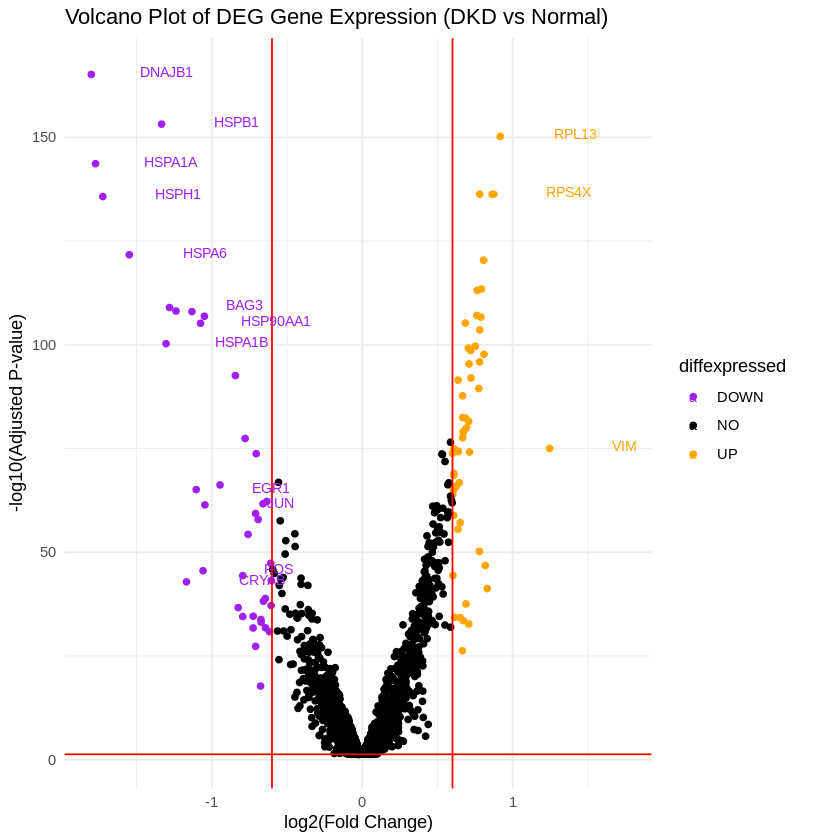

In [ ]:
# Add a column for differential expression status
Result_2$diffexpressed <- "NO"
# if logFC > 0.6 and FDR < 0.05, set as 'UP'
Result_2$diffexpressed[Result_2$logFC > 0.6 & Result_2$adj.P.Val < 0.05] <- "UP"
# if logFC < -0.6 and FDR < 0.05, set as 'DOWN'
Result_2$diffexpressed[Result_2$logFC < -0.6 & Result_2$adj.P.Val < 0.05] <- "DOWN"

# label genes with a large change
Result_2$delabel <- NA
Result_2$delabel[Result_2$diffexpressed != "NO" & abs(Result_2$logFC) > 0.85] <-
  rownames(Result_2[Result_2$diffexpressed != "NO" & abs(Result_2$logFC) > 0.85, ])

# colours are assigned in alphabetical order of the groups: DOWN, NO, UP
volcano_plot <- ggplot(data = Result_2, aes(x = logFC, y = -log10(adj.P.Val), col = diffexpressed, label = delabel)) +
  geom_point() +
  theme_minimal() +
  scale_color_manual(values = c("purple", "black", "orange")) +
  geom_vline(xintercept = c(-0.6, 0.6), col = "red") +
  geom_hline(yintercept = -log10(0.05), col = "red") +
  geom_text(size = 3, nudge_x = 0.5, nudge_y = 0.5, check_overlap = TRUE) +
  ggtitle("Volcano Plot of DEG Gene Expression (DKD vs Normal)") +
  xlab("log2(Fold Change)") +
  ylab("-log10(Adjusted P-value)")

print(volcano_plot)
# ggsave(file.path(proj_dir, "volcano_plot_DEG.png"), plot = volcano_plot, width = 10, height = 8, dpi = 300)

In [ ]:
head(Result_2, 10)

,logFC,AveExpr,t,P.Value,adj.P.Val,B,diffexpressed,delabel
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
DNAJB1,-1.801067,2.1209179,-33.32123,3.465025e-170,7.289374e-166,374.56497,DOWN,DNAJB1
HSPA1A,-1.772888,2.6310680,-30.29114,4.457444e-148,2.344281e-144,323.66149,DOWN,HSPA1A
HSPH1,-1.724774,1.5904678,-29.15776,7.462139e-140,1.962263e-136,304.73016,DOWN,HSPH1
HSPA6,-1.548628,0.9470432,-27.20406,8.633418e-126,2.018013e-122,272.36018,DOWN,HSPA6
HSPB1,-1.334532,2.1615181,-31.64049,6.577562e-158,6.918608e-154,346.29474,DOWN,HSPB1
HSPA1B,-1.304262,2.1050309,-24.10740,5.845848e-104,5.589959e-101,222.12498,DOWN,HSPA1B
BAG3,-1.281409,0.9673433,-25.38866,6.596376e-113,1.067446e-109,242.71220,DOWN,BAG3
VIM,1.245641,0.8005296,20.30923,1.976749e-78,9.670900e-76,163.40909,UP,VIM
HSPD1,-1.238168,1.7449250,-25.26350,5.002273e-112,7.516629e-109,240.68759,DOWN,HSPD1


**Interpreting the top genes.** The strongest changes are almost all **heat-shock / chaperone genes** (DNAJB1, HSPA1A, HSPA1B, HSPH1, HSPA6, HSPB1, HSPD1, BAG3, CRYAB), all with a negative log fold-change, i.e. *higher in Normal*. This pattern is a classic **tissue-handling / dissociation stress signature** and often reflects differences in sample collection or processing between groups rather than disease biology, so it needs to be interpreted with care. Genes related to the disease itself should be looked for further down the list, after checking whether the stress response differs between the Normal and DKD samples.

Possible next steps: pathway / GO enrichment of the UP and DOWN genes, repeating the comparison in other cell types (change `deg_celltypes`), and, as a more conservative alternative to cell-level tests, a pseudobulk comparison with one value per sample.